# Predicting extubation failure

Logistic regression and XGBoost predict recorded reintubation or death within 48 hours of planned extubation, using MIMIC-IV v3.1. The prespecified primary analysis uses the filtered cohort and six-hour means; full-cohort and last-hour analyses are prespecified sensitivity analyses.

Development data are used only to build the models (nested cross-validation, model selection, threshold, final refit) and to describe what the models learned (variable importance). Every performance table and figure comes from the temporal test set. Outputs are printed and saved under `models/outputs/`.

## 1. Setup


In [1]:
from pathlib import Path
from copy import deepcopy
import csv
import hashlib
import importlib.metadata
import json
import platform
import re
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss,
    confusion_matrix, log_loss, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import DMatrix, XGBClassifier

from IPython.display import display, Image

# Locate the project folder (the one containing data/) from wherever the notebook is opened.
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook within the group project folder containing data/.")


## 2. Settings

Edit `CONFIG`, then run top to bottom once. Every analysis choice (grids, model-selection rule, threshold rule, sensitivity analyses) is fixed in advance and tuning is automatic, so development and test evaluation run in the same pass. All models are built and frozen before any test patient is scored. A rerun with unchanged settings reloads the saved models and results; after the test has been scored, a rerun with changed settings or data is rejected.

| Analysis | Role fixed before test evaluation |
|---|---|
| `filtered_six_hour` | Primary: filtered cohort, six-hour means |
| `full_six_hour` | Prespecified missingness-filter sensitivity: full eligible cohort |
| `filtered_last_hour` | Prespecified feature sensitivity: same main-cohort patients and folds |

The full eligible cohort is different from the complete test partition of the primary cohort. It does not become primary because its test results are available. New missingness thresholds belong in development-only exploratory checks; do not select them using test performance.

Fewer than 20 events or non-events triggers a warning, without removing test patients. This is a precision warning, not a formal sample-size rule.

In [2]:
CONFIG = {
    "data_files": {
        "filtered": str(PROJECT_ROOT / "data/average_6h_filtered_dataset.csv"),
        "full": str(PROJECT_ROOT / "data/average_6h_full_dataset.csv"),
    },
    "coverage_csv": str(PROJECT_ROOT / "data/average_6h_coverage.csv"),
    "last_hour_csv": str(PROJECT_ROOT / "data/clean_full_final.csv"),
    "metadata_csv": None,  # optional sidecar if temporal fields are absent from the CSVs
    "output_root": str(PROJECT_ROOT / "models/outputs"),
    "include_last_hour_ablation": True,
    "target": "combined_outcome",
    "seed": 42,
    "split_mode": "temporal",
    "temporal_cutoff": 2020,  # same calendar-year boundary for every analysis
    "min_test_events": 20,    # warning only; all test patients are evaluated
    "feature_columns": None,  # None: use recognised physiological predictors; audit is saved
    "categorical_columns": ["gender", "sex", "first_careunit", "icu_type_at_admission"],
    "rsbi_column": None,      # None: use the RSBI summary available in each feature set
    "negative_followup_policy": "retain_recorded_labels",  # report uncertainty; do not redefine the cohort

    # Nested cross-validation and exhaustive grids (GridSearchCV).
    "outer_folds": 5,
    "inner_folds": 3,
    "lr_c_values": [0.001, 0.01, 0.1, 1, 10, 100],
    "lr_max_iter": 3000,
    "xgb_param_grid": {       # 2 x 3 x 2 x 2 x 2 = 48 combinations
        "n_estimators": [200, 400],
        "max_depth": [2, 3, 4],
        "learning_rate": [0.03, 0.1],
        "min_child_weight": [1, 5],
        "reg_lambda": [1, 10],
    },
    "xgb_subsample": 0.8,
    "xgb_colsample_bytree": 0.8,
    "xgb_threads": 4,

    # Evaluation.
    "calibrate": True,
    "calibration_method": "sigmoid",
    "sensitivity_target": 0.80,            # exploratory threshold target, not clinically validated
    "decision_curve_max_threshold": 0.30,  # decision curve covers risk thresholds 1% to this value
    "bootstrap_replicates": 1000,
}


## 3. Inputs and temporal split

Files in `data/`:
- `average_6h_filtered_dataset.csv`: main cohort, before median imputation.
- `average_6h_full_dataset.csv`: full-cohort sensitivity.
- `average_6h_coverage.csv`: observation counts and supplied filter membership; validation only, never predictors.
- `clean_full_final.csv`: bin 5 for the optional feature sensitivity, joined to exactly the main-cohort patients. Static covariates, index events and labels must agree.

Each patient needs `extubation_time`, `anchor_year`, and `anchor_year_group`. Include these in both averaged CSVs, or set `metadata_csv` to a file with one row per `subject_id` and these fields (preferably `stay_id` too). The current averaged exports include all three temporal fields. They are used only for splitting.

Predictors cover `[t−6 h, t)`, prediction is at planned extubation `t`, and the outcome window is `(t, t+48 h]`, with no gap. Eligibility and exclusions, including unplanned extubation, come from the phenotyping notebook. Supplied patients and labels are retained; imputation is learned inside training folds.

MIMIC-IV dates are shifted per patient. Map the extubation year to its possible calendar-year interval using `anchor_year` and `anchor_year_group`. Entirely pre-2020 intervals form development; intervals entirely from 2020 form test. Intervals crossing the cutoff are excluded because their temporal order is uncertain. The same cutoff and partition apply to every analysis.

The notebook checks duplicate IDs/columns, labels, shared rows, coverage and broad physiological ranges. It reports implausible values without changing them. `hospital_observed_48h` is follow-up metadata, never a predictor; incomplete observation among negatives is reported.


In [3]:
REQUIRED_CONFIG = {
    "data_csv", "metadata_csv", "output_dir", "target", "seed", "split_mode",
    "temporal_cutoff", "min_test_events", "feature_columns", "categorical_columns",
    "rsbi_column", "outer_folds", "inner_folds", "lr_c_values", "lr_max_iter",
    "xgb_param_grid", "xgb_subsample", "xgb_colsample_bytree", "xgb_threads",
    "calibrate", "calibration_method", "sensitivity_target", "decision_curve_max_threshold",
    "bootstrap_replicates", "analysis", "feature_set", "coverage_csv", "last_hour_csv",
    "suite_output_dir", "negative_followup_policy", "pipeline_version",
}

PHYSIOLOGY = {
    "heart_rate", "mbp", "sbp", "dbp", "resp_rate", "temperature", "spo2",
    "respiratory_rate_total", "respiratory_rate_spontaneous",
    "tidal_volume_observed", "tidal_volume_spontaneous", "fio2", "peep",
    "plateau_pressure", "minute_volume", "minute_ventilation", "po2", "pco2",
    "ph", "fio2_bg", "fio2_chartevents", "pao2fio2ratio", "bicarbonate",
    "baseexcess", "lactate", "rsbi",
}
BASELINE = {"age", "admission_age", "gender", "sex", "first_careunit", "icu_type_at_admission",
    "icu_hours_before_extubation", "hospital_hours_before_extubation"}
OUTCOME_COMPONENTS = ["death_within_48_hours", "reintubation_within_48_hours"]
MODEL_NAMES = ["logistic_regression", "xgboost"]
PROBABILITY_MODELS = MODEL_NAMES + ["prevalence_baseline"]

# Broad limits for error detection only: values outside them are counted and reported, never changed.
# Units follow the extraction notebook: FiO2 as a fraction, tidal volume in mL, temperature in degrees C.
PLAUSIBLE_RANGES = {
    "heart_rate": (20, 250), "mbp": (20, 200), "sbp": (40, 300), "dbp": (10, 200),
    "resp_rate": (1, 80), "respiratory_rate_total": (1, 80), "respiratory_rate_spontaneous": (1, 80),
    "temperature": (30, 43), "spo2": (50, 100),
    "tidal_volume_observed": (50, 2000), "tidal_volume_spontaneous": (50, 2000),
    "fio2": (0.21, 1.0), "fio2_bg": (0.21, 1.0), "fio2_chartevents": (0.21, 1.0),
    "peep": (0, 30), "plateau_pressure": (0, 60), "minute_volume": (0.5, 40), "minute_ventilation": (0.5, 40),
    "po2": (20, 700), "pco2": (10, 150), "ph": (6.8, 7.8), "pao2fio2ratio": (20, 1000),
    "bicarbonate": (2, 60), "baseexcess": (-40, 40), "lactate": (0.1, 30), "rsbi": (1, 1000),
    "age": (18, 110), "admission_age": (18, 110),
}


def validate_config(config):
    """Reject missing, unknown or inconsistent settings before any data are read."""
    cfg = deepcopy(config)
    missing = sorted(REQUIRED_CONFIG - set(cfg))
    if missing:
        raise ValueError("CONFIG is missing: " + str(missing))
    unknown = sorted(set(cfg) - REQUIRED_CONFIG)
    if unknown:
        raise ValueError("Unknown CONFIG settings: " + str(unknown))
    if cfg["calibration_method"] not in {"sigmoid", "isotonic"}:
        raise ValueError("calibration_method must be 'sigmoid' or 'isotonic'.")
    if cfg["negative_followup_policy"] not in {"retain_recorded_labels", "require_complete_negatives"}:
        raise ValueError("Unknown negative_followup_policy.")
    if cfg["split_mode"] != "temporal" or cfg["temporal_cutoff"] is None:
        raise ValueError("These analyses require a common, explicit temporal cutoff.")
    if int(cfg["min_test_events"]) < 1:
        raise ValueError("min_test_events must be at least 1.")
    if not 0 < cfg["decision_curve_max_threshold"] < 1:
        raise ValueError("decision_curve_max_threshold must be between 0 and 1.")
    if int(cfg["bootstrap_replicates"]) < 10:
        raise ValueError("bootstrap_replicates must be at least 10; intervals are always reported.")
    return cfg


def make_run_configs(config):
    """Give every cohort/feature analysis its own output folder."""
    cfg = deepcopy(config)
    files = cfg.pop("data_files")
    root = Path(cfg.pop("output_root"))
    include_ablation = cfg.pop("include_last_hour_ablation")
    cfg["pipeline_version"] = "six-hour-means-5"  # change when outputs change, so old caches are not reused
    cfg["suite_output_dir"] = str(root)
    specs = [("filtered_six_hour", "filtered", "six_hour"),
             ("full_six_hour", "full", "six_hour")]
    if include_ablation:
        specs.append(("filtered_last_hour", "filtered", "last_hour"))
    return {name: validate_config({**deepcopy(cfg), "analysis": name,
        "feature_set": feature_set, "data_csv": files[cohort],
        "output_dir": str(root / name)}) for name, cohort, feature_set in specs}


def write_json(path, value):
    """Save settings, converting NumPy scalars and paths to JSON values."""
    def encode(x):
        if isinstance(x, np.generic):
            return x.item()
        if isinstance(x, Path):
            return str(x)
        raise TypeError(f"Cannot encode {type(x)}")
    Path(path).write_text(json.dumps(value, indent=2, default=encode), encoding="utf-8")


def file_hash(path):
    """SHA-256 of a file, used to detect changed inputs or models."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def binary_series(s, name):
    """Require observed binary labels."""
    out = pd.to_numeric(s, errors="raise")
    if out.isna().any() or not out.isin([0, 1]).all():
        raise ValueError(f"{name} must contain only observed 0/1 labels.")
    return out.astype(int)


def forbidden_feature(name, target):
    """Identifiers, outcomes and post-prediction times must never be predictors."""
    n = name.lower()
    return (n == target.lower() or n in {"subject_id", "hadm_id", "stay_id", "dod", "label", "y"}
            or bool(re.search(r"outcome|death|deathtime|reintubat|discharg|dischtime|outtime|expire|los_|length_of_stay|followup|follow_up|hospital_observed|anchor_year|extubation_time|admittime|icu_intime|charttime|storetime|specimen_id|observed_values|missingness|retained_by", n)))


def feature_family(name):
    """Map an hourly bin or window summary (e.g. RSBI_bin_5) to its variable (rsbi)."""
    return re.sub(r"(_bin_[0-5]|_(mean|std|sd|min|max|last|slope|count|missing)(?:_6h)?|_6h)$", "", name.lower())


def recognised_feature(name):
    """Static covariates and physiological variables are the default predictors."""
    return name.lower() in BASELINE or feature_family(name) in PHYSIOLOGY


def range_audit(df, columns):
    """Count predictor values outside PLAUSIBLE_RANGES; the data are not modified."""
    rows = []
    for c in columns:
        limits = PLAUSIBLE_RANGES.get(feature_family(c))
        if limits is None or not pd.api.types.is_numeric_dtype(df[c]):
            continue
        v = df[c].dropna()
        rows.append({"column": c, "lower_limit": limits[0], "upper_limit": limits[1],
            "observed": len(v), "below": int((v < limits[0]).sum()), "above": int((v > limits[1]).sum()),
            "min": v.min() if len(v) else np.nan, "max": v.max() if len(v) else np.nan})
    audit = pd.DataFrame(rows, columns=["column", "lower_limit", "upper_limit", "observed", "below", "above", "min", "max"])
    audit["implausible_fraction"] = (audit.below + audit.above) / audit.observed.replace(0, np.nan)
    return audit


def race_group(s):
    """Collapse MIMIC race strings into broad groups for description and subgroup checks only."""
    s = s.fillna("UNKNOWN").astype(str).str.upper()
    return np.select([s.str.contains("WHITE"), s.str.contains("BLACK"),
        s.str.contains("HISPANIC|LATINO"), s.str.contains("ASIAN")],
        ["White", "Black", "Hispanic/Latino", "Asian"], default="Other/unknown")


In [4]:
def load_cohort(cfg):
    """Read one cohort CSV, check it and select predictors. Predictor values are not altered."""
    path = Path(cfg["data_csv"])
    if not path.exists():
        raise FileNotFoundError(f"CSV not found: {path.resolve()}. Set data_csv to the full cohort before median imputation and splitting.")
    if path.stem.startswith(("train_set", "test_set", "X_train", "X_test")):
        raise ValueError("Use the full cohort before median imputation and splitting.")
    # Check duplicate headers before pandas renames them.
    with path.open(newline="", encoding="utf-8-sig") as f:
        header = next(csv.reader(f))
    if len(header) != len(set(header)):
        raise ValueError("Duplicate CSV column names; fix the export.")
    df = pd.read_csv(path, dtype={"subject_id": "string", "stay_id": "string", "hadm_id": "string"})
    if "subject_id" not in df or cfg["target"] not in df:
        raise ValueError("Required columns: subject_id and " + cfg["target"])
    if df.subject_id.isna().any() or df.subject_id.duplicated().any():
        raise ValueError("Expected ONE row per subject_id, with a single index extubation.")
    # Keep splits reproducible if input rows are reordered.
    df = df.sort_values("subject_id").reset_index(drop=True)
    df[cfg["target"]] = binary_series(df[cfg["target"]], cfg["target"])
    components_present = [c in df for c in OUTCOME_COMPONENTS]
    if all(components_present):
        for c in OUTCOME_COMPONENTS:
            df[c] = binary_series(df[c], c)
        if not np.array_equal(df[cfg["target"]], df[OUTCOME_COMPONENTS].max(axis=1)):
            raise ValueError("combined_outcome disagrees with death OR reintubation.")
    else:
        warnings.warn("Outcome components are missing; cannot verify the combined label.")
    last_hour_path = None
    if cfg["feature_set"] == "last_hour":
        # Keep the averaged main cohort; replace only its physiological summaries.
        last_hour_path = Path(cfg["last_hour_csv"])
        hourly = pd.read_csv(last_hour_path, dtype={"subject_id": "string", "stay_id": "string", "hadm_id": "string"})
        if hourly.subject_id.isna().any() or hourly.subject_id.duplicated().any():
            raise ValueError("The hourly CSV must have one non-missing row per subject_id.")
        if not set(df.subject_id).issubset(set(hourly.subject_id)):
            raise ValueError("The hourly CSV does not cover every main-cohort patient.")
        hourly = hourly.set_index("subject_id").loc[df.subject_id].reset_index()
        matched = [c for c in ["stay_id", "hadm_id", cfg["target"], *OUTCOME_COMPONENTS,
            "hospital_observed_48h", *sorted(BASELINE)] if c in df]
        if not set(matched).issubset(hourly.columns):
            raise ValueError("The hourly CSV lacks the fields needed to verify the same patients/index events.")
        try:
            pd.testing.assert_frame_equal(df[matched], hourly[matched], check_dtype=False)
        except AssertionError:
            raise ValueError("Hourly and averaged CSVs disagree in index events, static covariates or outcomes.") from None
        means = [c for c in df if c.endswith("_mean_6h") and feature_family(c) in PHYSIOLOGY]
        bins = [c for c in hourly if c.endswith("_bin_5") and feature_family(c) in PHYSIOLOGY]
        if {feature_family(c) for c in means} != {feature_family(c) for c in bins}:
            raise ValueError("Six-hour and last-hour inputs must cover the same physiological variables.")
        df = pd.concat([df.drop(columns=means), hourly[bins]], axis=1)
    metadata_path = Path(cfg["metadata_csv"]) if cfg.get("metadata_csv") else None
    if metadata_path:
        if not metadata_path.exists():
            raise FileNotFoundError(f"Metadata CSV not found: {metadata_path}")
        meta = pd.read_csv(metadata_path, dtype={"subject_id": "string", "stay_id": "string", "hadm_id": "string"})
        if "subject_id" not in meta or meta.subject_id.isna().any() or meta.subject_id.duplicated().any():
            raise ValueError("Metadata must have one non-missing row per subject_id.")
        # Overlapping columns must agree before merging metadata.
        both = sorted((set(meta.columns) & set(df.columns)) - {"subject_id"})
        joined = df[["subject_id"] + both].merge(meta, on="subject_id", how="left", validate="one_to_one", suffixes=("_main", "_meta"))
        for c in both:
            a, b = joined[c + "_main"], joined[c + "_meta"]
            if not a.astype("string").fillna("<NA>").eq(b.astype("string").fillna("<NA>")).all():
                raise ValueError(f"Main CSV and metadata disagree in {c}; resolve before modelling.")
        extra = [c for c in meta if c not in df]
        df = df.merge(meta[["subject_id"] + extra], on="subject_id", how="left", validate="one_to_one")
    followup_col = next((c for c in ["hospital_observed_48h", "followup_complete"] if c in df), None)
    if followup_col:
        original = df[followup_col]
        known = pd.to_numeric(original.replace({True: 1, False: 0, "True": 1, "False": 0,
            "true": 1, "false": 0}), errors="coerce")
        if (original.notna() & (known.isna() | ~known.isin([0, 1]))).any():
            raise ValueError(f"{followup_col} must contain 0/1, booleans or missing values.")
        df[followup_col] = known
    else:
        known = pd.Series(np.nan, index=df.index)
    incomplete_negative = df[cfg["target"]].eq(0) & known.ne(1)
    if cfg["negative_followup_policy"] == "require_complete_negatives" and incomplete_negative.any():
        raise ValueError("Negative labels lack complete follow-up. Resolve the phenotype; no rows were silently dropped.")
    requested = cfg.get("feature_columns")
    selected = list(requested) if requested is not None else [c for c in df if recognised_feature(c)]
    if not selected or len(set(selected)) != len(selected):
        raise ValueError("No recognised predictors or duplicate features. Set feature_columns explicitly.")
    if not set(selected).issubset(df.columns):
        raise ValueError("Feature columns missing: " + str(sorted(set(selected) - set(df.columns))))
    leaks = [c for c in selected if forbidden_feature(c, cfg["target"])]
    if leaks:
        raise ValueError("Forbidden identifier/outcome/future predictors: " + str(leaks))
    cats = [c for c in selected if c in cfg["categorical_columns"]]
    nums = [c for c in selected if c not in cats]
    if not nums:
        raise ValueError("No numeric physiological predictors selected.")
    # Type conversion only: infinite values cannot be imputed, so they are treated as missing.
    for c in nums:
        df[c] = pd.to_numeric(df[c], errors="raise").replace([np.inf, -np.inf], np.nan)
    for c in cats:
        df[c] = df[c].astype(object).where(df[c].notna(), np.nan)
    rsbi_candidates = [cfg["rsbi_column"]] if cfg.get("rsbi_column") else ["RSBI_bin_5", "rsbi_bin_5", "RSBI_mean_6h", "rsbi_mean_6h", "RSBI", "rsbi"]
    rsbi_col = next((c for c in rsbi_candidates if c in df), None)
    if cfg.get("rsbi_column") and rsbi_col is None:
        raise ValueError("Configured rsbi_column is absent.")
    if rsbi_col:
        df[rsbi_col] = pd.to_numeric(df[rsbi_col], errors="raise").replace([np.inf, -np.inf], np.nan)
    else:
        warnings.warn("No RSBI column; skipping the RSBI comparison.")
    audit = pd.DataFrame({"column": df.columns})
    audit["used_as_predictor"] = audit.column.isin(selected)
    audit["reason"] = ["predictor" if c in selected else "blocked ID/outcome/time/follow-up" if forbidden_feature(c, cfg["target"]) else "metadata or unrecognised: not selected" for c in audit.column]
    hashes = {"data_csv_sha256": file_hash(path)}
    if last_hour_path:
        hashes["last_hour_csv_sha256"] = file_hash(last_hour_path)
    hashes["coverage_csv_sha256"] = file_hash(cfg["coverage_csv"])
    if metadata_path and metadata_path.exists():
        hashes["metadata_csv_sha256"] = file_hash(metadata_path)
    return df, nums, cats, rsbi_col, audit, hashes


def followup_summary(df, cfg):
    """Count labels without complete 48-hour hospital observation."""
    col = next((c for c in ["hospital_observed_48h", "followup_complete"] if c in df), None)
    observed = df[col].eq(1) if col else pd.Series(False, index=df.index)
    return {"followup_field": col, "patients": len(df),
        "negative_labels_without_complete_observation": int((df[cfg["target"]].eq(0) & ~observed).sum()),
        "known_events_without_complete_observation": int((df[cfg["target"]].eq(1) & ~observed).sum()),
        "policy": cfg["negative_followup_policy"]}


In [5]:
def make_split(df, cfg):
    """Assign each patient to development, test or ambiguous_time (excluded) by real calendar year."""
    manifest = df[["subject_id"]].copy()
    manifest["partition"] = "ambiguous_time"
    if cfg["split_mode"] == "temporal":
        required = ["extubation_time", "anchor_year", "anchor_year_group"]
        missing = [c for c in required if c not in df]
        if missing:
            raise ValueError("Temporal holdout needs " + str(missing) + ". Include them in data_csv or metadata_csv, keyed by subject_id.")
        groups = df.anchor_year_group.astype(str).str.extract(r"^\s*(\d{4})\s*[-–]\s*(\d{4})\s*$").astype(float)
        anchor = pd.to_numeric(df.anchor_year, errors="coerce")
        year = pd.to_datetime(df.extubation_time, errors="coerce").dt.year
        if groups.isna().any().any() or anchor.isna().any() or year.isna().any():
            raise ValueError("Temporal metadata contain missing or invalid values.")
        if (groups[1] < groups[0]).any() or (anchor % 1 != 0).any():
            raise ValueError("Invalid anchor year or year-group interval.")
        offset = year - anchor
        # Map shifted extubation years to possible calendar-year intervals.
        manifest["possible_year_lower"] = (groups[0] + offset).astype(int)
        manifest["possible_year_upper"] = (groups[1] + offset).astype(int)
        cutoff = cfg["temporal_cutoff"]
        manifest.loc[manifest.possible_year_upper < cutoff, "partition"] = "development"
        manifest.loc[manifest.possible_year_lower >= cutoff, "partition"] = "test"
        split_note = {"mode": "temporal", "cutoff": int(cutoff), "rule": "development: upper possible year < cutoff; test: lower possible year >= cutoff; overlapping intervals excluded", "cutoff_choice": "explicit, chosen without model performance"}
    else:
        raise ValueError("split_mode must be temporal.")
    dev = np.flatnonzero(manifest.partition.eq("development"))
    test = np.flatnonzero(manifest.partition.eq("test"))
    if not len(dev) or not len(test):
        raise ValueError("Empty development/test set. Check year intervals and temporal_cutoff.")
    assert not set(df.iloc[dev].subject_id) & set(df.iloc[test].subject_id)
    # Validate fold sizes using development labels only.
    checked_cv(df.iloc[dev][cfg["target"]].to_numpy(), cfg["outer_folds"], cfg["seed"])
    return manifest, dev, test, split_note


def checked_cv(y, folds, seed):
    """Stratified folds, after checking each class has enough patients."""
    counts = np.bincount(np.asarray(y, dtype=int), minlength=2)
    if folds < 2 or min(counts) < folds:
        raise ValueError(f"Need at least {folds} patients in each class for cross-validation; found {counts.tolist()}.")
    return list(StratifiedKFold(folds, shuffle=True, random_state=seed).split(np.zeros(len(y)), y))


def holdout_status(df, test_idx, cfg):
    """Count test patients and events only; no model is applied to the holdout here."""
    y = df.iloc[test_idx][cfg["target"]]
    events, non_events = int(y.sum()), int(len(y) - y.sum())
    return {"test_patients": len(y), "test_events": events,
        "test_non_events": non_events,
        "small_sample_warning": min(events, non_events) < cfg["min_test_events"],
        "rule": f"warn below {cfg['min_test_events']} events or non-events; retain all test patients"}


def warn_small_holdout(status, cfg):
    """Low event counts affect precision, not eligibility for evaluation."""
    if status["small_sample_warning"]:
        warnings.warn(f"{cfg['analysis']}: temporal holdout has {status['test_events']} events and "
            f"{status['test_non_events']} non-events (warning threshold: {cfg['min_test_events']}). "
            "All test patients are retained. Estimates and bootstrap intervals may be unstable; "
            "metrics requiring both outcome classes are undefined if one class is absent.")


def check_inputs(config):
    """Check inputs, fold sizes and holdout size without training or scoring test patients."""
    cfg = validate_config(config)
    df, nums, cats, rsbi_col, _, _ = load_cohort(cfg)
    manifest, dev, test, _ = make_split(df, cfg)
    y = df.iloc[dev][cfg["target"]].to_numpy()
    for fold, (train, _) in enumerate(checked_cv(y, cfg["outer_folds"], cfg["seed"])):
        checked_cv(y[train], cfg["inner_folds"], cfg["seed"] + fold + 1)
    holdout = holdout_status(df, test, cfg)
    warn_small_holdout(holdout, cfg)
    audit = range_audit(df, nums)
    return {"patients": len(df), "development_patients": len(dev),
        "development_events": int(y.sum()), "test_patients": holdout["test_patients"],
        "test_events": holdout["test_events"], "test_non_events": holdout["test_non_events"],
        "small_holdout_warning": holdout["small_sample_warning"],
        "excluded_ambiguous_year": int(manifest.partition.eq("ambiguous_time").sum()),
        "predictors": len(nums) + len(cats), "events_per_predictor": round(y.sum() / (len(nums) + len(cats)), 2),
        "values_outside_plausible_range": int(audit.below.sum() + audit.above.sum()),
        "rsbi_comparator": rsbi_col, "outer_folds": cfg["outer_folds"], "inner_folds": cfg["inner_folds"],
        "calibration": cfg["calibration_method"] if cfg["calibrate"] else "disabled",
        "development_negatives_without_complete_followup": followup_summary(df.iloc[dev], cfg)["negative_labels_without_complete_observation"]}


def validate_coverage(filtered, full, coverage_csv):
    """Check the supplied missingness audit; do not apply a new patient filter."""
    coverage = pd.read_csv(coverage_csv, dtype={"subject_id": "string", "stay_id": "string"})
    if coverage.subject_id.isna().any() or coverage.subject_id.duplicated().any():
        raise ValueError("Coverage must contain one row per subject_id.")
    if set(coverage.subject_id) != set(full.subject_id):
        raise ValueError("Coverage and full cohort must contain the same patients.")
    coverage = coverage.set_index("subject_id").loc[full.subject_id].reset_index()
    if not coverage.stay_id.equals(full.stay_id):
        raise ValueError("Coverage and full cohort refer to different ICU stays.")
    retained = coverage.retained_by_missingness_filter.map({True: True, False: False,
        "True": True, "False": False, "true": True, "false": False})
    if retained.isna().any() or set(coverage.loc[retained, "subject_id"]) != set(filtered.subject_id):
        raise ValueError("Coverage retention flags do not match the supplied filtered cohort.")
    means = [c for c in full if c.endswith("_mean_6h") and feature_family(c) in PHYSIOLOGY]
    if not means:
        raise ValueError("No six-hour mean features found in the averaged cohort CSVs.")
    if not np.allclose(full[means].isna().mean(axis=1), coverage.average_feature_missingness):
        raise ValueError("Coverage missingness disagrees with the averaged features.")
    for c in means:
        count = c.removesuffix("_mean_6h") + "_observed_values_6h"
        if count not in coverage:
            raise ValueError(f"Coverage is missing {count}.")
        observed = pd.to_numeric(coverage[count], errors="raise")
        if observed.isna().any() or (observed < 0).any() or (observed % 1 != 0).any():
            raise ValueError(f"Coverage counts must be non-negative integers: {count}.")
        if not np.array_equal(observed.eq(0), full[c].isna()):
            raise ValueError(f"Coverage counts disagree with missing values in {c}.")
    return {"full_patients": len(full), "filtered_patients": len(filtered),
        "removed_by_supplied_filter": len(full) - len(filtered), "mean_features": len(means)}


def prepare_analyses(configs):
    """Lock shared predictors and check that cohorts represent the same index events."""
    configs = deepcopy(configs)
    main = configs["filtered_six_hour"]
    filtered, nums, cats, _, _, _ = load_cohort(main)
    features = nums + cats
    full, full_nums, full_cats, _, _, _ = load_cohort(configs["full_six_hour"])
    coverage_summary = validate_coverage(filtered, full, main["coverage_csv"])
    print("Six-hour input validation:", coverage_summary)
    if set(features) != set(full_nums + full_cats):
        raise ValueError("Filtered and full cohorts must have the same predictor definitions.")
    if not set(filtered.subject_id).issubset(set(full.subject_id)):
        raise ValueError("The filtered cohort must be a subset of the full eligible cohort.")
    shared = full.set_index("subject_id").loc[filtered.subject_id].reset_index()
    optional = ["stay_id", "hadm_id", *OUTCOME_COMPONENTS, "hospital_observed_48h", "followup_complete"]
    one_sided = [c for c in optional if (c in filtered) != (c in full)]
    if one_sided:
        raise ValueError("Columns present in only one cohort CSV: " + str(one_sided))
    temporal = ["extubation_time", "anchor_year", "anchor_year_group"]
    check_columns = features + [main["target"]] + [c for c in temporal if c in filtered and c in full]
    check_columns += [c for c in optional if c in filtered]
    try:
        pd.testing.assert_frame_equal(filtered[check_columns].reset_index(drop=True),
            shared[check_columns].reset_index(drop=True), check_dtype=False,
            check_exact=False, rtol=1e-8, atol=1e-10)
    except AssertionError:
        raise ValueError("Shared patients have inconsistent features, outcomes or index-event metadata across the two CSVs.") from None
    for cfg in [configs["filtered_six_hour"], configs["full_six_hour"]]:
        cfg["feature_columns"] = features.copy()
    if "filtered_last_hour" in configs:
        last_cfg = configs["filtered_last_hour"]
        last_cfg["feature_columns"] = None
        _, last_nums, last_cats, _, _, _ = load_cohort(last_cfg)
        expected = {feature_family(c) for c in features}
        if expected != {feature_family(c) for c in last_nums + last_cats}:
            raise ValueError("The last-hour sensitivity must use the same variables as the main model.")
        last_cfg["feature_columns"] = last_nums + last_cats
    main_manifest, _, _, _ = make_split(filtered, main)
    full_manifest, _, _, _ = make_split(full, configs["full_six_hour"])
    matching = full_manifest.set_index("subject_id").loc[filtered.subject_id, "partition"].to_numpy()
    if not np.array_equal(main_manifest.partition.to_numpy(), matching):
        raise ValueError("Shared patients must have the same temporal partition in both cohorts.")
    return configs


def environment_versions():
    """Package versions saved with every analysis."""
    versions = {p: importlib.metadata.version(p) for p in
        ["numpy", "pandas", "scikit-learn", "xgboost", "scipy", "matplotlib", "joblib"]}
    return {**versions, "python": platform.python_version()}


def suite_plan(configs):
    """Settings, input hashes and environment that must stay fixed once the holdout is opened."""
    return {"analyses": {name: {"config": cfg, "source_hashes": load_cohort(cfg)[-1]}
        for name, cfg in configs.items()}, "environment": environment_versions()}


def guard_final_suite(configs):
    """Once any holdout is evaluated, all analyses must keep their frozen inputs/models."""
    marker = Path(next(iter(configs.values()))["suite_output_dir"]) / "final_suite_started.json"
    if not marker.exists():
        return
    saved = json.loads(marker.read_text())
    if saved["plan"] != suite_plan(configs):
        raise RuntimeError("Final evaluation has started. Restore the frozen analysis set, settings, data and environment.")
    for name, cfg in configs.items():
        out = Path(cfg["output_dir"])
        if file_hash(out / "trained_models.joblib") != saved["model_hashes"][name]:
            raise RuntimeError("A model changed after final evaluation started.")
        if file_hash(out / "frozen_analysis.json") != saved["analysis_hashes"][name]:
            raise RuntimeError("Frozen analysis metadata changed after final evaluation started.")


In [6]:
RUN_CONFIGS = make_run_configs(CONFIG)
RUN_CONFIGS = prepare_analyses(RUN_CONFIGS)
guard_final_suite(RUN_CONFIGS)
SUITE_DIR = Path(next(iter(RUN_CONFIGS.values()))["suite_output_dir"])
SUITE_DIR.mkdir(parents=True, exist_ok=True)

# One row per analysis: cohort size, events, holdout feasibility and data-quality counts.
INPUT_CHECKS = pd.DataFrame({name: check_inputs(cfg) for name, cfg in RUN_CONFIGS.items()}).T
INPUT_CHECKS.to_csv(SUITE_DIR / "input_checks.csv")
display(INPUT_CHECKS)
print("Package versions:", environment_versions())

# Error detection for the extraction step: implausible values are counted, not changed.
# The full cohort contains every filtered patient, so one audit covers both.
_full, _full_nums = load_cohort(RUN_CONFIGS["full_six_hour"])[:2]
RANGE_AUDIT = range_audit(_full, _full_nums)
RANGE_AUDIT.to_csv(SUITE_DIR / "predictor_range_audit_full_cohort.csv", index=False)
flagged = RANGE_AUDIT[(RANGE_AUDIT.below + RANGE_AUDIT.above) > 0]
if len(flagged):
    warnings.warn(f"{len(flagged)} predictor columns contain values outside PLAUSIBLE_RANGES; report them to the extraction step.")
    display(flagged.sort_values("implausible_fraction", ascending=False))

Six-hour input validation: {'full_patients': 19021, 'filtered_patients': 17146, 'removed_by_supplied_filter': 1875, 'mean_features': 19}


/var/folders/0y/926bml0x27j90kg_6jr1s2h00000gn/T/ipykernel_47904/2419519276.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  hourly = hourly.set_index("subject_id").loc[df.subject_id].reset_index()
/var/folders/0y/926bml0x27j90kg_6jr1s2h00000gn/T/ipykernel_47904/2419519276.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  hourly = hourly.set_index("subject_id").loc[df.subject_id].reset_index()


,patients,development_patients,development_events,test_patients,test_events,test_non_events,small_holdout_warning,excluded_ambiguous_year,predictors,events_per_predictor,values_outside_plausible_range,rsbi_comparator,outer_folds,inner_folds,calibration,development_negatives_without_complete_followup
filtered_six_hour,17146,15493,1503,897,106,791,False,756,24,62.62,161,RSBI_mean_6h,5,3,sigmoid,496
full_six_hour,19021,17034,2059,1093,163,930,False,894,24,85.79,172,RSBI_mean_6h,5,3,sigmoid,672
filtered_last_hour,17146,15493,1503,897,106,791,False,756,24,62.62,212,RSBI_bin_5,5,3,sigmoid,496


/var/folders/0y/926bml0x27j90kg_6jr1s2h00000gn/T/ipykernel_47904/1088160664.py:19: UserWarning: 10 predictor columns contain values outside PLAUSIBLE_RANGES; report them to the extraction step.
  warnings.warn(f"{len(flagged)} predictor columns contain values outside PLAUSIBLE_RANGES; report them to the extraction step.")


,column,lower_limit,upper_limit,observed,below,above,min,max,implausible_fraction
16,bicarbonate_mean_6h,2.0,60.0,28,0,1,12.500000,97.000000,0.035714
7,tidal_volume_spontaneous_mean_6h,50.0,2000.0,14792,31,72,1.000000,580221.000000,0.006963
12,RSBI_mean_6h,1.0,1000.0,13476,6,18,0.436144,29230.769231,0.001781
8,tidal_volume_observed_mean_6h,50.0,2000.0,18070,18,3,1.000000,250264.000000,0.001162
6,respiratory_rate_spontaneous_mean_6h,1.0,80.0,14424,0,7,1.000000,470.000000,0.000485
5,spo2_mean_6h,50.0,100.0,18958,6,0,36.000000,100.000000,0.000316
9,minute_volume_mean_6h,0.5,40.0,18488,1,4,0.010000,391.300000,0.000270
4,temperature_mean_6h,30.0,43.0,16712,2,0,26.110000,41.330000,0.000120
10,peep_mean_6h,0.0,30.0,18581,0,2,0.000000,45.000000,0.000108
15,po2_mean_6h,20.0,700.0,10554,1,0,16.000000,566.000000,0.000095


## 4. Study design figure

Figure 1 shows the predictor window, the prediction time and the outcome window. The cohort table (Table 1) is produced in Section 9, once the test set has been opened.

In [7]:
def plot_study_timeline(folder):
    """Timeline figure: predictor window, prediction time and outcome window (hours from extubation)."""
    fig, (before, after) = plt.subplots(1, 2, figsize=(10, 2.6), sharey=True,
        gridspec_kw={"width_ratios": [1, 1.6], "wspace": 0.04})
    before.axvspan(-6, 0, color="tab:blue", alpha=.2)
    before.axvspan(-1, 0, color="tab:blue", alpha=.35)
    before.text(-3.5, .7, "Predictors\nsix-hour means\n[t − 6 h, t)", ha="center", va="center", fontsize=9)
    before.text(-0.5, .2, "last-hour\nsensitivity", ha="center", va="center", fontsize=7)
    before.set(xlim=(-6.3, 0), xticks=range(-6, 1), ylim=(0, 1), yticks=[])
    after.axvspan(0, 48, color="tab:red", alpha=.15)
    after.text(24, .6, "Outcome window (t, t + 48 h]\nreintubation or death", ha="center", va="center", fontsize=9)
    after.text(1, .12, "t = planned extubation: prediction time, no gap", fontsize=8)
    after.set(xlim=(0, 48.5), xticks=[12, 24, 36, 48])  # 0 is labelled on the left panel
    for ax in (before, after):
        ax.axvline(0, color="k", lw=2)
        for side in ["left", "right", "top"]:
            ax.spines[side].set_visible(False)
    fig.supxlabel("Hours relative to planned extubation (t)", fontsize=9, y=-0.06)
    fig.savefig(folder / "study_timeline.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


def describe_group(d, features, target):
    """Table 1 column for one group of patients."""
    def pct(mask):
        return f"{int(mask.sum())} ({100 * mask.mean():.1f}%)" if len(d) else ""
    def median_iqr(values, digits):
        q = values.quantile([.25, .5, .75])
        return f"{q[.5]:.{digits}f} [{q[.25]:.{digits}f}–{q[.75]:.{digits}f}]"
    row = {"Patients, n": str(len(d))}
    age_col = next((c for c in ["admission_age", "age"] if c in d), None)
    if age_col and len(d):
        row["Age, median [IQR]"] = median_iqr(d[age_col], 0)
    sex_col = next((c for c in ["gender", "sex"] if c in d), None)
    if sex_col:
        row["Female, n (%)"] = pct(d[sex_col].astype(str).str.upper().str.startswith("F"))
    if "race" in d:
        groups = pd.Series(race_group(d["race"]), index=d.index)
        for g in ["White", "Black", "Hispanic/Latino", "Asian", "Other/unknown"]:
            row[f"Race: {g}, n (%)"] = pct(groups.eq(g))
    for c, label in [("icu_hours_before_extubation", "ICU hours before extubation"),
                     ("hospital_hours_before_extubation", "Hospital hours before extubation")]:
        if c in d and len(d):
            row[label + ", median [IQR]"] = median_iqr(d[c], 1)
    icu = next((c for c in ["icu_type_at_admission", "first_careunit"] if c in d), None)
    if icu:
        for category, count in d[icu].value_counts(sort=False).items():  # categories keep cohort order
            row[f"ICU type: {category}, n (%)"] = f"{count} ({100 * count / len(d):.1f}%)"
    row["Extubation failure, n (%)"] = pct(d[target].eq(1))
    for c, label in [("death_within_48_hours", "  Death within 48 h"),
                     ("reintubation_within_48_hours", "  Reintubation within 48 h")]:
        if c in d:
            row[label + ", n (%)"] = pct(d[c].eq(1))
    followup_col = next((c for c in ["hospital_observed_48h", "followup_complete"] if c in d), None)
    if followup_col:
        row["Negative labels without complete 48-h observation, n"] = str(int((d[target].eq(0) & d[followup_col].ne(1)).sum()))
    row["Model predictors missing, mean %"] = f"{100 * d[features].isna().to_numpy().mean():.1f}" if len(d) else ""
    return row


def cohort_table(runs):
    """Table 1: development and test partitions of the primary cohort, and patients removed by the filter."""
    primary, full = runs["filtered_six_hour"], runs["full_six_hour"]
    bundle = primary["bundle"]
    target = bundle["frozen"]["config"]["target"]
    features = bundle["frozen"]["selected_features"]
    everyone = full["data"].copy()
    icu = next((c for c in ["icu_type_at_admission", "first_careunit"] if c in everyone), None)
    if icu:
        # ICU types with fewer than 20 patients overall are grouped for display.
        counts = everyone[icu].value_counts()
        grouped = everyone[icu].where(everyone[icu].isin(counts[counts >= 20].index), "Other")
        everyone[icu] = pd.Categorical(grouped, categories=grouped.value_counts().index)
    everyone = everyone.set_index("subject_id", drop=False)
    removed = ~everyone.subject_id.isin(primary["data"].subject_id)
    groups = {"Development": everyone.loc[bundle["development_ids"]],
              "Temporal test": everyone.loc[bundle["test_ids"]],
              "Removed by missingness filter (all years)": everyone.loc[removed],
              "Full eligible cohort (all years)": everyone}
    table = pd.DataFrame({name: describe_group(d, features, target) for name, d in groups.items()})
    return table.fillna("0 (0.0%)").rename_axis("Characteristic").reset_index()

Table 1: development patients by outcome and missingness-filter membership


,Main cohort: no failure,Main cohort: failure,Main cohort: all,Removed by missingness filter,Full cohort: all
"Patients, n",13990,1503,15493,1541,17034
"Age, median [IQR]",66 [55–76],69 [58–80],66 [55–76],64 [50–77],66 [55–76]
"Female, n (%)",5267 (37.6%),632 (42.0%),5899 (38.1%),680 (44.1%),6579 (38.6%)
"Extubation failure, n (%)",0 (0.0%),1503 (100.0%),1503 (9.7%),556 (36.1%),2059 (12.1%)
"Death within 48 h, n (%)",0 (0.0%),720 (47.9%),720 (4.6%),498 (32.3%),1218 (7.2%)
"Reintubation within 48 h, n (%)",0 (0.0%),801 (53.3%),801 (5.2%),61 (4.0%),862 (5.1%)
"Incomplete or unknown 48-h hospital observation, n (%)",496 (3.5%),723 (48.1%),1219 (7.9%),675 (43.8%),1894 (11.1%)
"Negative labels without complete 48-h observation, n",496,0,496,176,672
"Model predictors missing, mean %",21.5,24.8,21.9,44.6,23.9


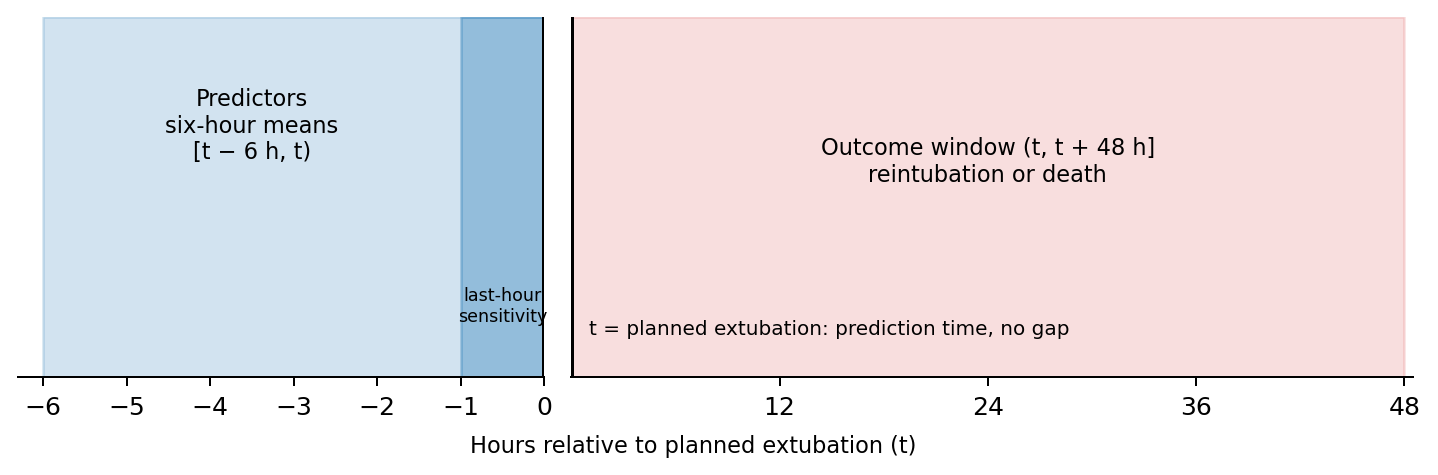

In [8]:
plot_study_timeline(SUITE_DIR)
display(Image(filename=str(SUITE_DIR / "study_timeline.png")))

## 5. Models, tuning and calibration

- **Models.** Logistic regression (LR, interpretable, linear effects) and XGBoost (black box, nonlinear effects and interactions).
- **Preprocessing.** Median imputation, plus standardisation for LR, is fitted inside each training fold, so no information from validation or test patients leaks in. Predictors are otherwise used as supplied: no missingness indicators or engineered features are added.
- **Tuning.** An exhaustive `GridSearchCV` runs in the inner folds and refits on AUROC. Average precision and log loss are recorded for each candidate. LR searches `C` over 0.001–100; XGBoost searches all 48 combinations in `xgb_param_grid`.
- **Class imbalance.** LR uses balanced class weights; XGBoost uses the training-fold negative/positive ratio (`scale_pos_weight`).
- **Calibration.** Class weighting inflates predicted risks, so each tuned pipeline is recalibrated with sigmoid (Platt) scaling, using cross-validated predictions within the training partition.

In [9]:
class FoldBalancedXGB(ClassifierMixin, BaseEstimator):
    """XGBoost whose scale_pos_weight is recalculated from each training fold."""
    def __init__(self, n_estimators=250, max_depth=3, learning_rate=0.05,
                 min_child_weight=1, reg_lambda=1, subsample=0.8,
                 colsample_bytree=0.8, random_state=42, n_jobs=4):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.min_child_weight = min_child_weight
        self.reg_lambda = reg_lambda
        self.subsample = subsample
        self.colsample_bytree = colsample_bytree
        self.random_state = random_state
        self.n_jobs = n_jobs

    def fit(self, X, y):
        counts = np.bincount(np.asarray(y, dtype=int), minlength=2)
        if min(counts) == 0:
            raise ValueError("XGBoost fit requires both classes.")
        # Negative/positive ratio of this training fold only.
        self.scale_pos_weight_ = float(counts[0] / counts[1])
        self.model_ = XGBClassifier(**self.get_params(), scale_pos_weight=self.scale_pos_weight_,
            objective="binary:logistic", eval_metric="logloss", tree_method="hist", device="cpu")
        self.model_.fit(X, y)
        self.classes_ = self.model_.classes_
        self.n_features_in_ = self.model_.n_features_in_
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

    def predict(self, X):
        return self.model_.predict(X)


def model_pipeline(name, nums, cats, cfg):
    """Fold-wise preprocessing and model. Entirely missing training columns are kept (imputed as 0)."""
    numeric = [("impute", SimpleImputer(strategy="median", keep_empty_features=True))]
    if name == "logistic_regression":
        numeric.append(("scale", StandardScaler()))
    parts = [("numeric", Pipeline(numeric), nums)]
    if cats:
        categorical = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="unknown", keep_empty_features=True)),
            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
        parts.append(("categorical", categorical, cats))
    prep = ColumnTransformer(parts, remainder="drop", sparse_threshold=0)
    if name == "logistic_regression":
        model = LogisticRegression(class_weight="balanced", solver="lbfgs", max_iter=cfg["lr_max_iter"], random_state=cfg["seed"])
    elif name == "xgboost":
        model = FoldBalancedXGB(random_state=cfg["seed"], n_jobs=cfg["xgb_threads"],
            subsample=cfg["xgb_subsample"], colsample_bytree=cfg["xgb_colsample_bytree"])
    else:
        raise ValueError(name)
    return Pipeline([("preprocess", prep), ("model", model)])


def fit_tuned(name, X, y, nums, cats, cfg, cv):
    """Exhaustive grid search on the given folds (refit on AUROC), then optional calibration."""
    pipe = model_pipeline(name, nums, cats, cfg)
    grid = ({"model__C": cfg["lr_c_values"]} if name == "logistic_regression"
            else {"model__" + key: values for key, values in cfg["xgb_param_grid"].items()})
    search = GridSearchCV(pipe, grid, cv=cv, refit="auroc", n_jobs=1, error_score="raise",
        scoring={"auroc": "roc_auc", "average_precision": "average_precision", "log_loss": "neg_log_loss"})
    search.fit(X, y)
    fitted = search.best_estimator_
    if cfg["calibrate"]:
        # Calibrate on cross-validated predictions within this training partition, then refit on all of it.
        fitted = CalibratedClassifierCV(clone(fitted), method=cfg["calibration_method"], cv=cv, ensemble=False, n_jobs=1)
        fitted.fit(X, y)
    cols = [c for c in search.cv_results_ if c == "params" or c.startswith(("mean_test_", "std_test_", "rank_test_", "mean_fit_"))]
    return fitted, search.best_params_, pd.DataFrame(search.cv_results_)[cols]

## 6. Test-set metrics and figures

All of these are computed on the temporal test set with the frozen models and thresholds.

- **Discrimination:** AUROC and average precision (AP, the step-based area under the precision–recall curve; compare it with prevalence).
- **Accuracy of predicted risks:** Brier score; scaled Brier = 1 − Brier / (prevalence × (1 − prevalence)), where 0 means no better than predicting the prevalence.
- **Calibration:** observed:expected (O:E) ratio and calibration slope (1 is ideal; a slope below 1 indicates overfitting), plus a calibration plot.
- **Classification:** sensitivity, specificity, PPV and NPV at the frozen threshold. The threshold is the development out-of-fold (OOF) value giving maximum specificity at ≥ 80% sensitivity; it is an exploratory operating point, not a clinically validated one.
- **Baselines:** prevalence and a fixed-seed random score. RSBI ≥ 105 is compared on the same RSBI-available patients; a six-hour RSBI summary is not the original bedside measurement.
- **Clinical utility:** a decision curve gives the net benefit of acting on alerts across risk thresholds of 1–30%, against acting on all, on none, or on RSBI ≥ 105 (RSBI-available patients).
- **Uncertainty:** patient bootstrap 95% intervals; paired bootstraps resample the same patients for both compared scores. Intervals are conditional on the fitted models.
- **Subgroups:** exploratory checks by sex, age group (< 65 or ≥ 65) and race group; small subgroups are unstable.

In [10]:
LABELS = {"logistic_regression": "Logistic regression", "xgboost": "XGBoost", "rsbi_ge_105": "RSBI ≥ 105",
    "treat_all": "Act on all", "treat_none": "Act on none"}
COLOURS = {"logistic_regression": "tab:blue", "xgboost": "tab:orange", "rsbi_ge_105": "tab:green",
    "treat_all": "grey", "treat_none": "black"}


def safe_ratio(a, b):
    return float(a / b) if b else np.nan


def calibration_summary(y, p):
    """Observed:expected ratio and calibration slope (outcome regressed on logit risk)."""
    p = np.clip(p, 1e-7, 1 - 1e-7)
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    oe = safe_ratio(y.sum(), p.sum())
    if len(np.unique(y)) < 2 or np.std(logit) < 1e-12:
        return oe, np.nan
    # A very large C makes this effectively an unpenalised logistic regression.
    slope = LogisticRegression(C=1e10, max_iter=1000).fit(logit, y).coef_[0, 0]
    return oe, float(slope)


def metrics(y, score, threshold=0.5, probability=True, calibration=True):
    """Discrimination, threshold and (for probabilities) calibration metrics."""
    y, score = np.asarray(y, int), np.asarray(score, float)
    keep = np.isfinite(score)
    y, score = y[keep], score[keep]
    if not len(y):
        return {"n": 0}
    two = len(np.unique(y)) == 2
    prevalence = float(y.mean())
    tn, fp, fn, tp = confusion_matrix(y, score >= threshold, labels=[0, 1]).ravel()
    result = {"n": len(y), "events": int(y.sum()), "prevalence": prevalence,
        "auroc": roc_auc_score(y, score) if two else np.nan,
        "average_precision": average_precision_score(y, score) if two else np.nan,
        "threshold": float(threshold), "sensitivity": safe_ratio(tp, tp + fn),
        "specificity": safe_ratio(tn, tn + fp), "ppv": safe_ratio(tp, tp + fp),
        "npv": safe_ratio(tn, tn + fn), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "brier": np.nan, "scaled_brier": np.nan, "log_loss": np.nan,
        "observed_expected_ratio": np.nan, "calibration_slope": np.nan}
    if probability:
        result["brier"] = brier_score_loss(y, score)
        result["scaled_brier"] = 1 - result["brier"] / (prevalence * (1 - prevalence)) if two else np.nan
        result["log_loss"] = log_loss(y, np.clip(score, 1e-7, 1 - 1e-7), labels=[0, 1])
        if calibration:
            result["observed_expected_ratio"], result["calibration_slope"] = calibration_summary(y, score)
    return result


def choose_threshold(y, score, sensitivity_target):
    """Maximise specificity at the target sensitivity using development OOF scores."""
    if not 0 < sensitivity_target <= 1:
        raise ValueError("sensitivity_target must be in (0,1].")
    fpr, tpr, thresholds = roc_curve(y, score, drop_intermediate=False)
    eligible = np.flatnonzero((tpr >= sensitivity_target) & np.isfinite(thresholds))
    # roc_curve thresholds descend: among tied FPR choose the highest threshold.
    best = eligible[np.argmin(fpr[eligible])]
    return float(thresholds[best])


def prediction_table(df, cfg, scores, rsbi_col, fold=None):
    """One row per patient: labels, evaluation-only descriptors and every model's score."""
    cols = [c for c in ["subject_id", "hadm_id", "stay_id", cfg["target"], *OUTCOME_COMPONENTS,
        "age", "admission_age", "gender", "sex", "race"] if c in df]
    out = df[cols].copy().reset_index(drop=True)
    out = out.rename(columns={cfg["target"]: "y_true"})
    for name, values in scores.items():
        out[name] = values
    if rsbi_col:
        out["rsbi"] = df[rsbi_col].to_numpy()
    if fold is not None:
        out["outer_fold"] = fold
    return out


def comparison_tables(predictions, thresholds, calibration=True):
    """Metrics for every model on all patients and on the RSBI-available subset."""
    rows = []
    scopes = {"all_patients": np.ones(len(predictions), dtype=bool)}
    if "rsbi" in predictions:
        scopes["rsbi_available_same_patients"] = np.isfinite(predictions.rsbi)
    for scope, mask in scopes.items():
        p = predictions.loc[mask]
        for name in PROBABILITY_MODELS + ["random_guess"]:
            if name in p:
                # Calibration metrics apply to probability models only.
                rows.append({"scope": scope, "model": name, **metrics(p.y_true, p[name],
                    thresholds.get(name, 0.5), name in PROBABILITY_MODELS, calibration)})
        if scope == "rsbi_available_same_patients":
            rows.append({"scope": scope, "model": "rsbi", **metrics(p.y_true, p.rsbi, 105, False)})
    return pd.DataFrame(rows)


def bootstrap_intervals(p, thresholds, cfg):
    """Patient bootstrap 95% intervals for every model, plus the paired XGBoost − LR difference."""
    rng = np.random.default_rng(cfg["seed"] + 200)
    samples, differences = [], []
    for rep in range(cfg["bootstrap_replicates"]):
        sample = p.iloc[rng.integers(0, len(p), len(p))]
        table = comparison_tables(sample, thresholds, calibration=False)
        for _, row in table.iterrows():
            for metric in ["auroc", "average_precision", "sensitivity", "specificity", "ppv", "npv", "brier", "scaled_brier"]:
                samples.append({"replicate": rep, "scope": row.scope, "model": row.model, "metric": metric, "value": row.get(metric, np.nan)})
        paired = table[table.scope.eq("all_patients")].set_index("model")
        for metric in ["auroc", "average_precision", "brier"]:
            differences.append({"replicate": rep, "metric": metric, "value": paired.loc["xgboost", metric] - paired.loc["logistic_regression", metric]})
    def summarise(frame, groups):
        # Single-class resamples give undefined AUROC/AP; only finite replicates are summarised.
        frame["value"] = frame["value"].where(np.isfinite(frame["value"]))
        return frame.groupby(groups).value.agg(valid_replicates="count", lower_95=lambda s: s.quantile(.025), upper_95=lambda s: s.quantile(.975)).reset_index()
    intervals = summarise(pd.DataFrame(samples), ["scope", "model", "metric"])
    paired_ci = summarise(pd.DataFrame(differences), ["metric"])
    point = comparison_tables(p, thresholds, calibration=False)
    point = point[point.scope.eq("all_patients")].set_index("model")
    paired_ci["n"], paired_ci["events"] = len(p), int(p.y_true.sum())
    for model in MODEL_NAMES:
        paired_ci[model] = paired_ci.metric.map(point.loc[model])
    paired_ci["xgboost_minus_logistic_regression"] = paired_ci.xgboost - paired_ci.logistic_regression
    paired_ci = paired_ci[["metric", "n", "events", "logistic_regression", "xgboost",
        "xgboost_minus_logistic_regression", "lower_95", "upper_95", "valid_replicates"]]
    return intervals, paired_ci


def paired_bootstrap(y, a, b, reps, seed):
    """Metrics of scores a and b and their difference (a − b) on the same resampled patients."""
    y, a, b = np.asarray(y, int), np.asarray(a, float), np.asarray(b, float)
    if not len(y):
        return []
    def values(i):
        two_classes = len(np.unique(y[i])) == 2
        return {"auroc": (roc_auc_score(y[i], a[i]), roc_auc_score(y[i], b[i])) if two_classes else (np.nan, np.nan),
                "average_precision": (average_precision_score(y[i], a[i]), average_precision_score(y[i], b[i])) if two_classes else (np.nan, np.nan),
                "brier": (brier_score_loss(y[i], a[i]), brier_score_loss(y[i], b[i]))}
    point = values(np.arange(len(y)))
    rng = np.random.default_rng(seed)
    draws = [values(rng.integers(0, len(y), len(y))) for _ in range(reps)]
    rows = []
    for metric, (va, vb) in point.items():
        diff = np.array([d[metric][0] - d[metric][1] for d in draws])
        diff = diff[np.isfinite(diff)]
        rows.append({"metric": metric, "a": va, "b": vb, "a_minus_b": va - vb,
            "lower_95": np.quantile(diff, .025) if len(diff) else np.nan,
            "upper_95": np.quantile(diff, .975) if len(diff) else np.nan, "valid_replicates": len(diff)})
    return rows


def rsbi_comparison(table, intervals):
    """LR, XGBoost and RSBI on the same RSBI-available patients, with AUROC/AP intervals."""
    scope = "rsbi_available_same_patients"
    columns = ["model", "n", "events", "auroc", "average_precision", "sensitivity", "specificity", "ppv", "npv"]
    matched = table.loc[table.scope.eq(scope) & table.model.isin(MODEL_NAMES + ["rsbi"])].reindex(columns=columns)
    for metric in ["auroc", "average_precision"]:
        ci = intervals.loc[intervals.scope.eq(scope) & intervals.metric.eq(metric), ["model", "lower_95", "upper_95"]]
        matched = matched.merge(ci.rename(columns={"lower_95": metric + "_lower_95", "upper_95": metric + "_upper_95"}),
            on="model", how="left", validate="one_to_one")
    return matched


def outcome_component_auroc(p):
    """AUROC for deaths and reintubations separately, each against patients with neither event."""
    rows = []
    negatives = p.y_true.eq(0)
    for component in OUTCOME_COMPONENTS:
        if component not in p:
            continue
        for name in MODEL_NAMES + (["rsbi"] if "rsbi" in p else []):
            keep = (negatives | p[component].eq(1)) & np.isfinite(p[name])
            y = p.loc[keep, component]
            rows.append({"component": component, "model": name, "events": int(y.sum()), "non_events": int((y == 0).sum()),
                "auroc": roc_auc_score(y, p.loc[keep, name]) if y.nunique() == 2 else np.nan})
    return pd.DataFrame(rows)


def bootstrap_auroc_ci(y, s, reps, seed):
    """Percentile bootstrap interval for one AUROC."""
    y, s = np.asarray(y, int), np.asarray(s, float)
    rng = np.random.default_rng(seed)
    values = []
    for _ in range(reps):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) == 2:
            values.append(roc_auc_score(y[i], s[i]))
    return (np.quantile(values, .025), np.quantile(values, .975)) if values else (np.nan, np.nan)


def subgroup_metrics(p, thresholds, cfg):
    """Exploratory performance by sex, age group and race group."""
    groups = pd.DataFrame(index=p.index)
    sex_col = next((c for c in ["gender", "sex"] if c in p), None)
    if sex_col:
        groups["sex"] = p[sex_col].astype(str)
    age_col = next((c for c in ["admission_age", "age"] if c in p), None)
    if age_col:
        groups["age_group"] = np.where(p[age_col] >= 65, ">=65", "<65")
    if "race" in p:
        groups["race_group"] = race_group(p["race"])
    rows = []
    for variable in groups:
        for value, idx in groups.groupby(variable).groups.items():
            g = p.loc[idx]
            for name in MODEL_NAMES:
                row = {"variable": variable, "group": value, "model": name,
                    **metrics(g.y_true, g[name], thresholds[name], calibration=False)}
                row["auroc_lower_95"], row["auroc_upper_95"] = bootstrap_auroc_ci(
                    g.y_true, g[name], min(cfg["bootstrap_replicates"], 500), cfg["seed"] + 500)
                rows.append(row)
    return pd.DataFrame(rows)


def net_benefit(y, flagged, threshold):
    """Net benefit of acting on flagged patients at one risk threshold (Vickers & Elkin 2006)."""
    n = len(y)
    tp = np.sum(flagged & (y == 1))
    fp = np.sum(flagged & (y == 0))
    return tp / n - fp / n * threshold / (1 - threshold)


def decision_curve(p, max_threshold, include_rsbi=False):
    """Net benefit of each model, act-on-all, act-on-none and (optionally) RSBI >= 105."""
    y = p.y_true.to_numpy()
    rows = []
    for t in np.round(np.arange(0.01, max_threshold + 1e-9, 0.005), 3):
        strategies = {name: p[name].to_numpy() >= t for name in MODEL_NAMES}
        if include_rsbi:
            strategies["rsbi_ge_105"] = p.rsbi.to_numpy() >= 105
        strategies["treat_all"] = np.ones(len(y), dtype=bool)
        rows += [{"threshold": t, "strategy": k, "net_benefit": net_benefit(y, v, t)} for k, v in strategies.items()]
        rows.append({"threshold": t, "strategy": "treat_none", "net_benefit": 0.0})
    return pd.DataFrame(rows)


def plot_auroc_forest(table, path, title):
    """AUROC with patient-bootstrap 95% CI for each analysis and model."""
    t = table[table.model.isin(MODEL_NAMES)].reset_index(drop=True)
    analyses = list(dict.fromkeys(t.analysis))
    fig, ax = plt.subplots(figsize=(8, 1.1 * len(analyses) + 1.2))
    for model, offset in [("logistic_regression", -.12), ("xgboost", .12)]:
        m = t[t.model.eq(model)]
        y = np.array([analyses.index(a) for a in m.analysis]) + offset
        ax.hlines(y, m.auroc_lower_95, m.auroc_upper_95, color=COLOURS[model])
        ax.plot(m.auroc, y, "o", color=COLOURS[model], label=LABELS[model])
    first = t.drop_duplicates("analysis")
    ax.set_yticks(range(len(analyses)), [f"{a}\n(n={int(n):,}, events={int(e):,})"
        for a, n, e in zip(first.analysis, first.n, first.events)])
    ax.axvline(.5, color="k", linestyle="--", alpha=.5)
    ax.invert_yaxis()
    ax.set(xlabel="AUROC (95% patient-bootstrap CI)", title=title)
    ax.legend(fontsize=8, loc="best")
    fig.tight_layout()
    fig.savefig(path, dpi=180, bbox_inches="tight")
    plt.close(fig)


def plot_calibration_and_utility(p, max_threshold, folder, title):
    """Calibration on all patients; decision curve on RSBI-available patients so RSBI >= 105 is a fair comparator."""
    folder = Path(folder)
    matched = p.loc[np.isfinite(p.rsbi)] if "rsbi" in p else p.iloc[:0]
    use_rsbi = matched.y_true.nunique() == 2
    if not use_rsbi:
        warnings.warn("RSBI comparison unavailable (no RSBI or one outcome class); showing all-patient decision curves.")
    elif min(int(matched.y_true.sum()), int((matched.y_true == 0).sum())) < 20:
        warnings.warn("RSBI decision curve has fewer than 20 events or non-events; interpret cautiously.")
    dca_patients = matched if use_rsbi else p
    curve = decision_curve(dca_patients, max_threshold, include_rsbi=use_rsbi)
    curve.to_csv(folder / "FINAL_decision_curve.csv", index=False)  # net-benefit values for the text

    fig, (cal, dca) = plt.subplots(1, 2, figsize=(11, 4.5))
    # Quantile bins with about ten or more events each, between 3 and 10 bins.
    n_bins = int(np.clip(p.y_true.sum() // 10, 3, 10))
    limit = .1
    for model in MODEL_NAMES:
        observed, predicted = calibration_curve(p.y_true, p[model], n_bins=n_bins, strategy="quantile")
        cal.plot(predicted, observed, "o-", color=COLOURS[model], label=LABELS[model])
        limit = max(limit, 1.15 * max(predicted.max(), observed.max()))
    limit = min(limit, 1)
    cal.plot([0, limit], [0, limit], "k--", alpha=.5, label="Ideal")
    cal.set(xlim=(0, limit), ylim=(0, limit), xlabel="Mean predicted risk", ylabel="Observed event rate",
        title=f"Calibration: all patients\n(n={len(p):,}, events={int(p.y_true.sum()):,})")
    for strategy, g in curve.groupby("strategy", sort=False):
        dca.plot(g.threshold, g.net_benefit, label=LABELS[strategy], color=COLOURS[strategy],
            linestyle="--" if strategy.startswith("treat") else "-")
    top = curve.net_benefit.max()
    if top > 0:
        dca.set(ylim=(-0.5 * top, 1.1 * top))  # act-on-all becomes very negative at high thresholds
    population = "RSBI-available patients" if use_rsbi else "all patients"
    dca.set(xlabel="Risk threshold for acting on an alert", ylabel="Net benefit",
        title=f"Decision curve: {population}\n(n={len(dca_patients):,}, events={int(dca_patients.y_true.sum()):,})")
    for ax in (cal, dca):
        ax.legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    path = folder / "FINAL_calibration_decision_curve.png"
    fig.savefig(path, dpi=180, bbox_inches="tight")
    plt.close(fig)
    return path

## 7. Model development (nested cross-validation)

Development patients are used only to build the models. In each of 5 outer folds, `GridSearchCV` tunes both models in 3 inner folds and the tuned, calibrated pipeline scores the held-out fold. The out-of-fold (OOF) predictions are used to choose the model (higher mean outer-fold AUROC) and to set each model's threshold (maximum specificity at ≥ 80% sensitivity). Both models are then retuned on all development patients; these frozen models are scored on the test set in Section 9.

The table below is a record for the Methods section (selected model, threshold, final hyperparameters, mean ± SD outer-fold AUROC), not a results table.

In [11]:
def run_development(config):
    """Nested CV for model selection and thresholds, then final refit on all development patients."""
    cfg = validate_config(config)
    out = Path(cfg["output_dir"])
    df, nums, cats, rsbi_col, audit, hashes = load_cohort(cfg)
    locked = (out / "final_test_started.json").exists() or (Path(cfg["suite_output_dir"]) / "final_suite_started.json").exists()
    cache_files = ["frozen_analysis.json", "trained_models.joblib", "development_oof_predictions.csv", "environment_versions.json"]
    cached = all((out / name).exists() for name in cache_files)
    reuse = False
    if cached or locked:
        frozen = json.loads((out / "frozen_analysis.json").read_text())
        reuse = (cached and cfg == frozen["config"] and hashes == frozen["source_hashes"]
            and json.loads((out / "environment_versions.json").read_text()) == environment_versions())
        if locked and not reuse:
            raise RuntimeError("Final test already opened and settings/data/environment changed. Restore the frozen analysis.")
    if reuse:
        bundle = joblib.load(out / "trained_models.joblib")
        dev = df.set_index("subject_id", drop=False).loc[bundle["development_ids"]].reset_index(drop=True)
        print("Reusing completed development: settings, source data and environment are unchanged.")
        return {"bundle": bundle, "data": df, "development": dev, "output_dir": out,
            "oof": pd.read_csv(out / "development_oof_predictions.csv", dtype={"subject_id": "string"})}
    manifest, dev_idx, test_idx, split_note = make_split(df, cfg)
    holdout = holdout_status(df, test_idx, cfg)
    out.mkdir(parents=True, exist_ok=True)
    dev = df.iloc[dev_idx].reset_index(drop=True)
    followup = followup_summary(dev, cfg)
    if followup["negative_labels_without_complete_observation"]:
        warnings.warn(f"{cfg['analysis']}: {followup['negative_labels_without_complete_observation']} development negatives lack complete 48-hour observation. Supplied labels are retained; describe this limitation.")
    X, y = dev[nums + cats], dev[cfg["target"]].to_numpy()

    # Outer loop: each fold's patients are scored by models tuned without them.
    outer = checked_cv(y, cfg["outer_folds"], cfg["seed"])
    scores = {name: np.full(len(dev), np.nan) for name in MODEL_NAMES}
    folds = np.full(len(dev), -1, dtype=int)
    fold_auroc = {name: [] for name in MODEL_NAMES}
    fold_parameters = []
    for fold, (train, valid) in enumerate(outer):
        inner = checked_cv(y[train], cfg["inner_folds"], cfg["seed"] + fold + 1)
        folds[valid] = fold
        for name in MODEL_NAMES:
            print(f"Outer fold {fold + 1}/{len(outer)}: {name}", flush=True)
            fitted, params, _ = fit_tuned(name, X.iloc[train], y[train], nums, cats, cfg, inner)
            scores[name][valid] = fitted.predict_proba(X.iloc[valid])[:, 1]
            fold_auroc[name].append(float(roc_auc_score(y[valid], scores[name][valid])))
            fold_parameters.append({"outer_fold": fold, "model": name, "parameters": params})
    assert all(np.isfinite(s).all() for s in scores.values()) and (folds >= 0).all()
    oof = prediction_table(dev, cfg, scores, rsbi_col, folds)
    oof.to_csv(out / "development_oof_predictions.csv", index=False)

    # Model selection and thresholds from development OOF predictions only.
    mean_auroc = {name: float(np.mean(v)) for name, v in fold_auroc.items()}
    winner = max(mean_auroc, key=mean_auroc.get)
    thresholds = {name: choose_threshold(y, scores[name], cfg["sensitivity_target"]) for name in MODEL_NAMES}
    thresholds.update({"prevalence_baseline": 0.5, "random_guess": 0.5})
    dev[nums + cats].isna().mean().rename("missing_fraction_development").to_csv(out / "development_feature_missingness.csv")
    audit.to_csv(out / "feature_audit.csv", index=False)

    # Final models: retuned on all development patients and frozen for the test set.
    final_models, final_params = {}, {}
    final_cv = checked_cv(y, cfg["inner_folds"], cfg["seed"] + 100)
    for name in MODEL_NAMES:
        print(f"Refitting {name} on development patients only", flush=True)
        final_models[name], final_params[name], _ = fit_tuned(name, X, y, nums, cats, cfg, final_cv)
    write_json(out / "environment_versions.json", environment_versions())
    frozen = {"config": cfg, "source_hashes": hashes, "split": split_note,
        "selected_features": nums + cats, "rsbi_column": rsbi_col,
        "partition_counts": manifest.partition.value_counts().to_dict(), "holdout": holdout,
        "thresholds": thresholds, "threshold_rule": "maximum specificity at development OOF sensitivity >= configured target",
        "selected_primary_model": winner, "selection_rule": "highest mean outer-fold AUROC, before final test",
        "outer_fold_auroc": fold_auroc, "mean_outer_fold_auroc": mean_auroc,
        "outer_fold_parameters": fold_parameters, "final_parameters": final_params,
        "development_n": len(dev), "development_events": int(y.sum()), "development_followup": followup,
        "test_outcomes_used_for_training_or_selection": False}
    write_json(out / "frozen_analysis.json", frozen)
    bundle = {"models": final_models, "frozen": frozen, "development_prevalence": float(y.mean()),
        "development_ids": dev.subject_id.tolist(), "test_ids": df.iloc[test_idx].subject_id.tolist()}
    joblib.dump(bundle, out / "trained_models.joblib")
    print(f"Development complete. Selected model: {winner}. Models frozen.")
    return {"bundle": bundle, "data": df, "development": dev, "oof": oof, "output_dir": out}


def model_selection_summary(runs):
    """Methods record: outer-fold AUROC, selected model, threshold and final hyperparameters."""
    rows = []
    for analysis, run in runs.items():
        frozen = run["bundle"]["frozen"]
        for name in MODEL_NAMES:
            auroc = frozen["outer_fold_auroc"][name]
            rows.append({"analysis": analysis, "model": name,
                "development_patients": frozen["development_n"], "development_events": frozen["development_events"],
                "outer_fold_auroc_mean": np.mean(auroc), "outer_fold_auroc_sd": np.std(auroc, ddof=1),
                "selected": name == frozen["selected_primary_model"], "threshold": frozen["thresholds"][name],
                "final_hyperparameters": {k.removeprefix("model__"): v for k, v in frozen["final_parameters"][name].items()}})
    return pd.DataFrame(rows)


def verify_ablation_pair(runs):
    """The last-hour analysis must use the same patients, split and folds as the main analysis."""
    if "filtered_last_hour" not in runs:
        return
    main, ablation = runs["filtered_six_hour"], runs["filtered_last_hour"]
    for field in ["development_ids", "test_ids"]:
        if main["bundle"][field] != ablation["bundle"][field]:
            raise ValueError("The feature ablation must use exactly the same patients and temporal split.")
    pd.testing.assert_frame_equal(main["oof"][["subject_id", "y_true", "outer_fold"]],
        ablation["oof"][["subject_id", "y_true", "outer_fold"]])


filtered_six_hour
Outer fold 1/5: logistic_regression


/var/folders/0y/926bml0x27j90kg_6jr1s2h00000gn/T/ipykernel_47904/1663477376.py:32: UserWarning: filtered_six_hour: 496 development negatives lack complete 48-hour observation. Supplied labels are retained; describe this limitation.
  warnings.warn(f"{cfg['analysis']}: {followup['negative_labels_without_complete_observation']} development negatives lack complete 48-hour observation. Supplied labels are retained; describe this limitation.")


Outer fold 1/5: xgboost
Outer fold 2/5: logistic_regression
Outer fold 2/5: xgboost
Outer fold 3/5: logistic_regression
Outer fold 3/5: xgboost
Outer fold 4/5: logistic_regression
Outer fold 4/5: xgboost
Outer fold 5/5: logistic_regression
Outer fold 5/5: xgboost
Refitting logistic_regression on development patients only
Refitting xgboost on development patients only
Development complete. Selected model: xgboost. Test not evaluated.

full_six_hour
Outer fold 1/5: logistic_regression


/var/folders/0y/926bml0x27j90kg_6jr1s2h00000gn/T/ipykernel_47904/1663477376.py:32: UserWarning: full_six_hour: 672 development negatives lack complete 48-hour observation. Supplied labels are retained; describe this limitation.
  warnings.warn(f"{cfg['analysis']}: {followup['negative_labels_without_complete_observation']} development negatives lack complete 48-hour observation. Supplied labels are retained; describe this limitation.")


Outer fold 1/5: xgboost
Outer fold 2/5: logistic_regression
Outer fold 2/5: xgboost
Outer fold 3/5: logistic_regression
Outer fold 3/5: xgboost
Outer fold 4/5: logistic_regression
Outer fold 4/5: xgboost
Outer fold 5/5: logistic_regression
Outer fold 5/5: xgboost
Refitting logistic_regression on development patients only
Refitting xgboost on development patients only
Development complete. Selected model: xgboost. Test not evaluated.

filtered_last_hour
Outer fold 1/5: logistic_regression


/var/folders/0y/926bml0x27j90kg_6jr1s2h00000gn/T/ipykernel_47904/2419519276.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  hourly = hourly.set_index("subject_id").loc[df.subject_id].reset_index()
/var/folders/0y/926bml0x27j90kg_6jr1s2h00000gn/T/ipykernel_47904/1663477376.py:32: UserWarning: filtered_last_hour: 496 development negatives lack complete 48-hour observation. Supplied labels are retained; describe this limitation.
  warnings.warn(f"{cfg['analysis']}: {followup['negative_labels_without_complete_observation']} development negatives lack complete 48-hour observation. Supplied labels are retained; describe this limitation.")


Outer fold 1/5: xgboost
Outer fold 2/5: logistic_regression
Outer fold 2/5: xgboost
Outer fold 3/5: logistic_regression
Outer fold 3/5: xgboost
Outer fold 4/5: logistic_regression
Outer fold 4/5: xgboost
Outer fold 5/5: logistic_regression
Outer fold 5/5: xgboost
Refitting logistic_regression on development patients only
Refitting xgboost on development patients only
Development complete. Selected model: xgboost. Test not evaluated.
Development OOF performance (threshold metrics are descriptive)


,analysis,model,n,events,mean_outer_fold_auroc,auroc,auroc_lower_95,auroc_upper_95,average_precision,brier,scaled_brier,calibration_slope,observed_expected_ratio,sensitivity,specificity,ppv
0,filtered_six_hour,logistic_regression,15493,1503,0.812,0.811,0.800,0.822,0.368,0.074,0.159,1.067,0.999,0.800,0.651,0.198
1,filtered_six_hour,xgboost,15493,1503,0.827,0.826,0.816,0.837,0.421,0.071,0.188,1.031,0.970,0.800,0.679,0.211
2,filtered_six_hour,prevalence_baseline,15493,1503,NaN,0.500,0.487,0.514,0.097,0.088,-0.000,0.833,1.000,0.000,1.000,NaN
3,filtered_six_hour,random_guess,15493,1503,NaN,0.506,0.491,0.521,0.100,NaN,NaN,NaN,NaN,0.514,0.501,0.100
4,full_six_hour,logistic_regression,17034,2059,0.821,0.821,0.811,0.831,0.437,0.085,0.198,1.016,1.000,0.800,0.672,0.251
5,full_six_hour,xgboost,17034,2059,0.849,0.848,0.839,0.857,0.522,0.079,0.258,1.025,0.972,0.800,0.715,0.279
6,full_six_hour,prevalence_baseline,17034,2059,NaN,0.500,0.491,0.509,0.121,0.106,-0.000,0.798,1.000,0.000,1.000,NaN
7,full_six_hour,random_guess,17034,2059,NaN,0.508,0.495,0.522,0.124,NaN,NaN,NaN,NaN,0.510,0.500,0.123
8,filtered_last_hour,logistic_regression,15493,1503,0.805,0.805,0.793,0.816,0.351,0.075,0.145,1.077,0.999,0.800,0.646,0.195
9,filtered_last_hour,xgboost,15493,1503,0.823,0.823,0.813,0.833,0.408,0.072,0.179,1.031,0.971,0.800,0.674,0.209


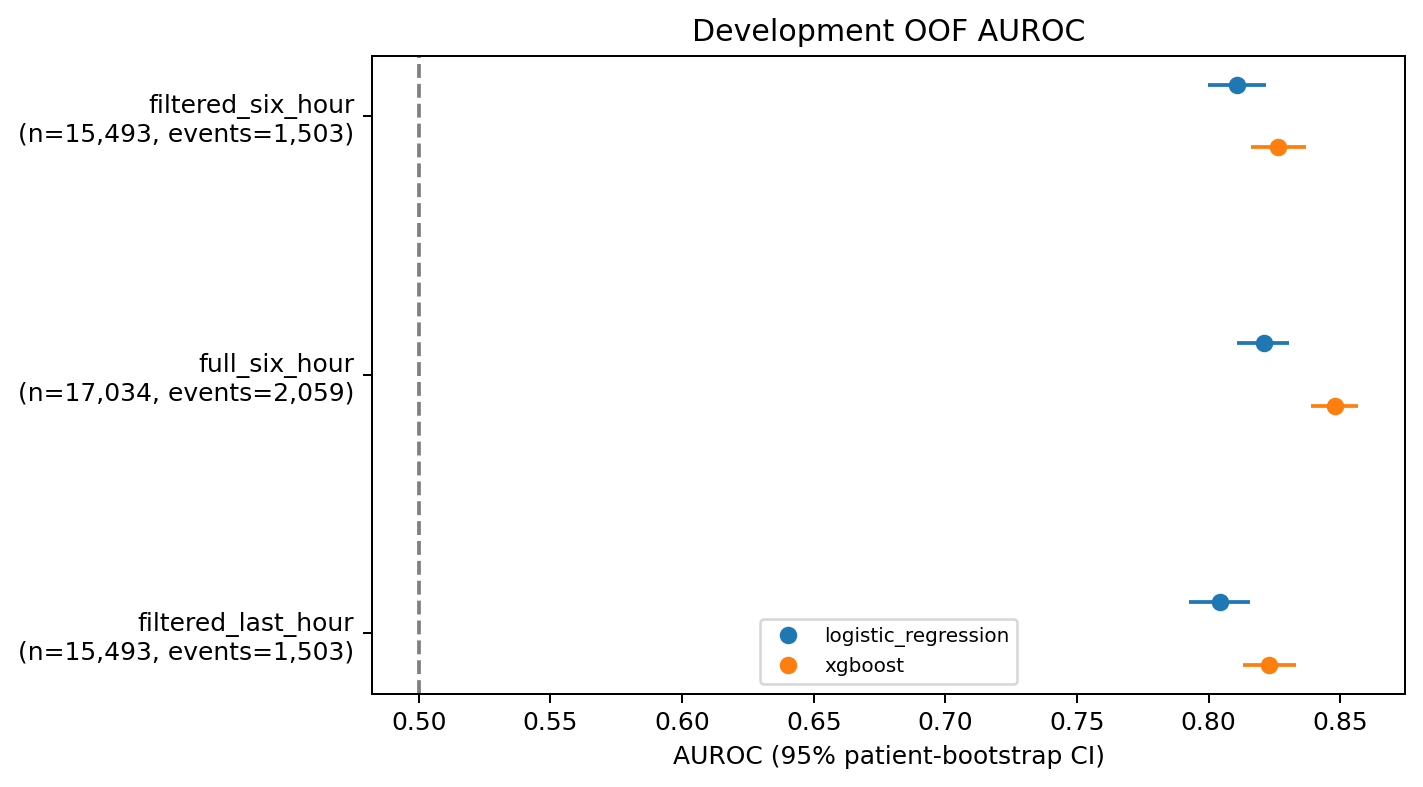

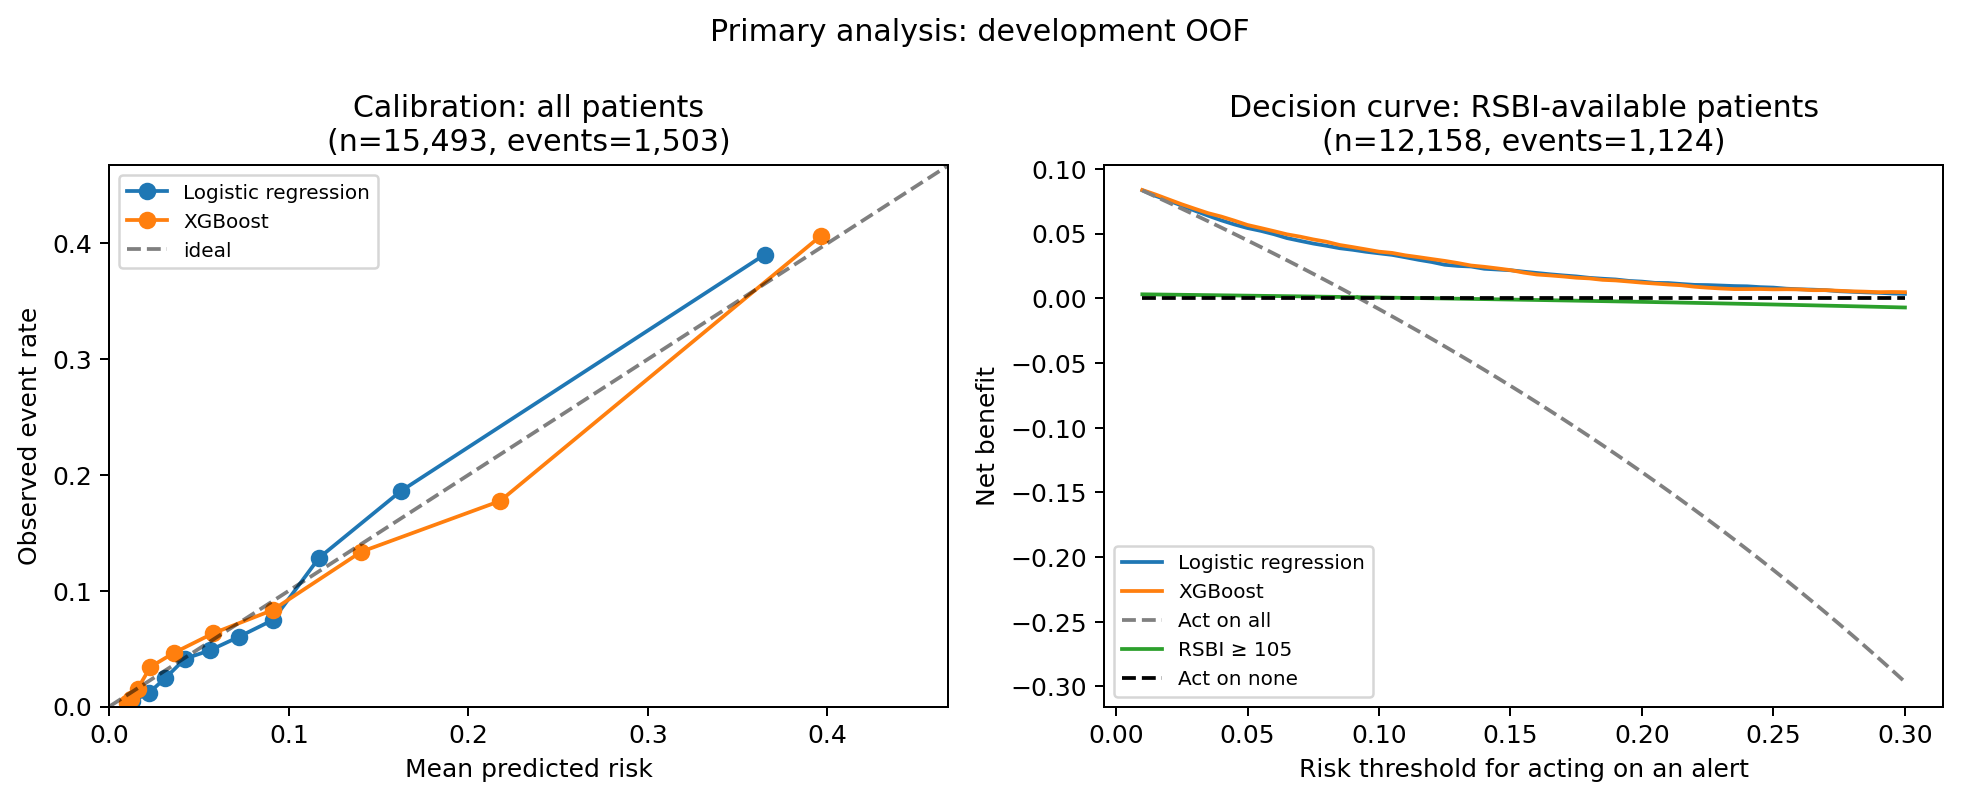

XGBoost minus LR, paired bootstrap (primary analysis)


,metric,n,events,logistic_regression,xgboost,xgboost_minus_logistic_regression,lower_95,upper_95,valid_replicates
0,auroc,15493,1503,0.811,0.826,0.016,0.010,0.021,1000
1,average_precision,15493,1503,0.368,0.421,0.052,0.039,0.065,1000
2,brier,15493,1503,0.074,0.071,-0.002,-0.003,-0.002,1000


LR, XGBoost and RSBI on the same RSBI-available development patients


,model,n,events,auroc,average_precision,sensitivity,specificity,ppv,npv,auroc_lower_95,auroc_upper_95,average_precision_lower_95,average_precision_upper_95
0,logistic_regression,12158,1124,0.765,0.261,0.778,0.605,0.167,0.964,0.752,0.779,0.239,0.288
1,xgboost,12158,1124,0.782,0.301,0.780,0.632,0.178,0.966,0.769,0.795,0.275,0.329
2,rsbi,12158,1124,0.565,0.113,0.036,0.973,0.119,0.908,0.548,0.583,0.105,0.123


Six-hour means minus last-hour values (same patients and folds)


...

,analysis,a,b,model,patients,events,metric,a_value,b_value,a_minus_b,lower_95,upper_95,valid_replicates
0,shared_main_cohort_patients,full-cohort training (OOF),filtered-cohort training (OOF),logistic_regression,15493,1503,auroc,0.807,0.811,-0.003,-0.006,-0.001,1000
1,shared_main_cohort_patients,full-cohort training (OOF),filtered-cohort training (OOF),logistic_regression,15493,1503,average_precision,0.379,0.368,0.011,0.005,0.017,1000
2,shared_main_cohort_patients,full-cohort training (OOF),filtered-cohort training (OOF),logistic_regression,15493,1503,brier,0.073,0.074,-0.001,-0.001,-0.000,1000
3,shared_main_cohort_patients,full-cohort training (OOF),filtered-cohort training (OOF),xgboost,15493,1503,auroc,0.825,0.826,-0.002,-0.005,0.002,1000
4,shared_main_cohort_patients,full-cohort training (OOF),filtered-cohort training (OOF),xgboost,15493,1503,average_precision,0.432,0.421,0.011,0.003,0.020,1000
5,shared_main_cohort_patients,full-cohort training (OOF),filtered-cohort training (OOF),xgboost,15493,1503,brier,0.071,0.071,-0.000,-0.001,0.000,1000
6,patients_removed_by_filter,full-cohort training (OOF),filtered-cohort final model,logistic_regression,1541,556,auroc,0.813,0.810,0.003,-0.001,0.008,1000
7,patients_removed_by_filter,full-cohort training (OOF),filtered-cohort final model,logistic_regression,1541,556,average_precision,0.666,0.659,0.007,0.000,0.015,1000
8,patients_removed_by_filter,full-cohort training (OOF),filtered-cohort final model,logistic_regression,1541,556,brier,0.208,0.228,-0.020,-0.023,-0.017,1000
9,patients_removed_by_filter,full-cohort training (OOF),filtered-cohort final model,xgboost,1541,556,auroc,0.837,0.820,0.017,0.010,0.024,1000


Deaths and reintubations separately against non-events (primary analysis)


,component,model,events,non_events,auroc
0,death_within_48_hours,logistic_regression,720,13990,0.906
1,death_within_48_hours,xgboost,720,13990,0.915
2,death_within_48_hours,rsbi,414,11034,0.573
3,reintubation_within_48_hours,logistic_regression,801,13990,0.724
4,reintubation_within_48_hours,xgboost,801,13990,0.745
5,reintubation_within_48_hours,rsbi,724,11034,0.560


Exploratory subgroups (primary analysis)


,variable,group,model,n,events,auroc,auroc_lower_95,auroc_upper_95
0,sex,F,logistic_regression,5899,632,0.789,0.771,0.807
1,sex,F,xgboost,5899,632,0.804,0.786,0.819
2,sex,M,logistic_regression,9594,871,0.824,0.811,0.837
3,sex,M,xgboost,9594,871,0.840,0.828,0.852
4,age_group,<65,logistic_regression,7106,584,0.791,0.773,0.810
5,age_group,<65,xgboost,7106,584,0.818,0.802,0.834
6,age_group,>=65,logistic_regression,8387,919,0.821,0.808,0.835
7,age_group,>=65,xgboost,8387,919,0.830,0.816,0.842


In [12]:
guard_final_suite(RUN_CONFIGS)
runs = {}
for analysis, cfg in RUN_CONFIGS.items():
    print(f"\n{analysis}", flush=True)
    runs[analysis] = run_development(cfg)
verify_ablation_pair(runs)
primary_dir = runs["filtered_six_hour"]["output_dir"]

# Record for Methods: selected model, thresholds and final hyperparameters (not a results table).
MODEL_SELECTION = model_selection_summary(runs)
MODEL_SELECTION.to_csv(SUITE_DIR / "model_selection.csv", index=False)
display(MODEL_SELECTION.round(3))

## 8. Development interpretation

Primary cohort, development patients only. Shows the ten largest numeric LR coefficients (log odds per SD after fold-median imputation) and the ten leading XGBoost variables by mean absolute TreeSHAP. Both describe the base models before calibration; SHAP sums encoded columns by source variable. Full tables are saved. These are predictive associations, not causal effects. Check the saved feature-missingness table before interpreting nearly all-missing predictors; their coefficients can be unstable.


In [13]:
def base_pipeline(model):
    """Uncalibrated tuned pipeline inside a calibrated model."""
    return model.calibrated_classifiers_[0].estimator if isinstance(model, CalibratedClassifierCV) else model


def transformed_variable(name, categorical):
    """Map a transformed column (numeric__RSBI_bin_3, categorical__gender_M) to its source variable."""
    prefix, _, column = name.partition("__")
    if prefix == "categorical":
        return next((c for c in categorical if column.startswith(c + "_")), column)
    return feature_family(column)


def export_interpretation(run):
    """Coefficient and SHAP tables plus one figure for the primary analysis."""
    bundle, dev, out = run["bundle"], run["development"], run["output_dir"]
    cfg = bundle["frozen"]["config"]
    features = bundle["frozen"]["selected_features"]
    categorical = [c for c in features if c in cfg["categorical_columns"]]

    lr = base_pipeline(bundle["models"]["logistic_regression"])
    names = lr.named_steps["preprocess"].get_feature_names_out()
    coefficients = pd.DataFrame({"feature": names, "variable": [transformed_variable(n, categorical) for n in names],
        "coefficient": lr.named_steps["model"].coef_[0]})
    coefficients["abs_coefficient"] = coefficients.coefficient.abs()
    coefficients = coefficients.sort_values("abs_coefficient", ascending=False)
    coefficients.to_csv(out / "logistic_base_coefficients.csv", index=False)

    # Native TreeSHAP contributions sum to the base model's log odds.
    xgb = base_pipeline(bundle["models"]["xgboost"])
    transformed = xgb.named_steps["preprocess"].transform(dev[features])
    booster = xgb.named_steps["model"].model_.get_booster()
    contrib = booster.predict(DMatrix(transformed), pred_contribs=True)
    margin = booster.predict(DMatrix(transformed), output_margin=True)
    np.testing.assert_allclose(contrib.sum(axis=1), margin, atol=1e-4, rtol=1e-4)
    columns = xgb.named_steps["preprocess"].get_feature_names_out()
    shap_frame = pd.DataFrame(contrib[:, :-1], columns=columns)
    pd.DataFrame({"feature": columns, "mean_abs_shap_log_odds": shap_frame.abs().mean().to_numpy()}).sort_values(
        "mean_abs_shap_log_odds", ascending=False).to_csv(out / "xgboost_base_treeshap_by_column.csv", index=False)
    # Combine encoded columns belonging to the same source variable.
    variables = np.array([transformed_variable(c, categorical) for c in columns])
    variable_shap = shap_frame.T.groupby(variables).sum().T
    importance = (variable_shap.abs().mean().sort_values(ascending=False)
        .rename("mean_abs_shap_log_odds").rename_axis("variable").reset_index())
    importance.to_csv(out / "xgboost_base_treeshap_by_variable.csv", index=False)

    # Figure: ten largest numeric LR coefficients and ten leading XGBoost variables.
    numeric_coefficients = coefficients[coefficients.feature.str.startswith("numeric__")].head(10).iloc[::-1]
    top = importance.head(10).iloc[::-1]
    fig, (lr_ax, xgb_ax) = plt.subplots(1, 2, figsize=(12, 4.8))
    lr_ax.barh(numeric_coefficients.variable, numeric_coefficients.coefficient, color="tab:blue")
    lr_ax.axvline(0, color="k", lw=.7)
    lr_ax.set(xlabel="Log odds per SD (base model)", title="A  Logistic regression")
    xgb_ax.barh(top.variable, top.mean_abs_shap_log_odds, color="tab:orange")
    xgb_ax.set(xlabel="Mean |TreeSHAP| (base-model log odds)", title="B  XGBoost")
    fig.tight_layout()
    fig.savefig(out / "interpretation_lr_shap.png", dpi=180, bbox_inches="tight")
    plt.close(fig)
    return coefficients, importance


,feature,variable,coefficient,abs_coefficient
24,categorical__icu_type_at_admission_Cardiac Vas...,icu_type_at_admission,-1.370,1.370
32,categorical__icu_type_at_admission_Neuro Surgi...,icu_type_at_admission,0.956,0.956
9,numeric__tidal_volume_spontaneous_mean_6h,tidal_volume_spontaneous,-0.724,0.724
1,numeric__icu_hours_before_extubation,icu_hours_before_extubation,0.433,0.433
12,numeric__peep_mean_6h,peep,0.354,0.354
0,numeric__admission_age,admission_age,0.347,0.347
29,categorical__icu_type_at_admission_Medical/Sur...,icu_type_at_admission,-0.254,0.254
5,numeric__resp_rate_mean_6h,resp_rate,0.251,0.251
33,categorical__icu_type_at_admission_PACU,icu_type_at_admission,0.227,0.227
35,categorical__icu_type_at_admission_Trauma SICU...,icu_type_at_admission,0.202,0.202


,variable,mean_abs_shap_log_odds
0,icu_hours_before_extubation,0.7562
1,icu_type_at_admission,0.4934
2,admission_age,0.2530
3,peep,0.1887
4,resp_rate,0.1829
5,heart_rate,0.1780
6,minute_volume,0.1167
7,spo2,0.0990
8,ph,0.0960
9,temperature,0.0877


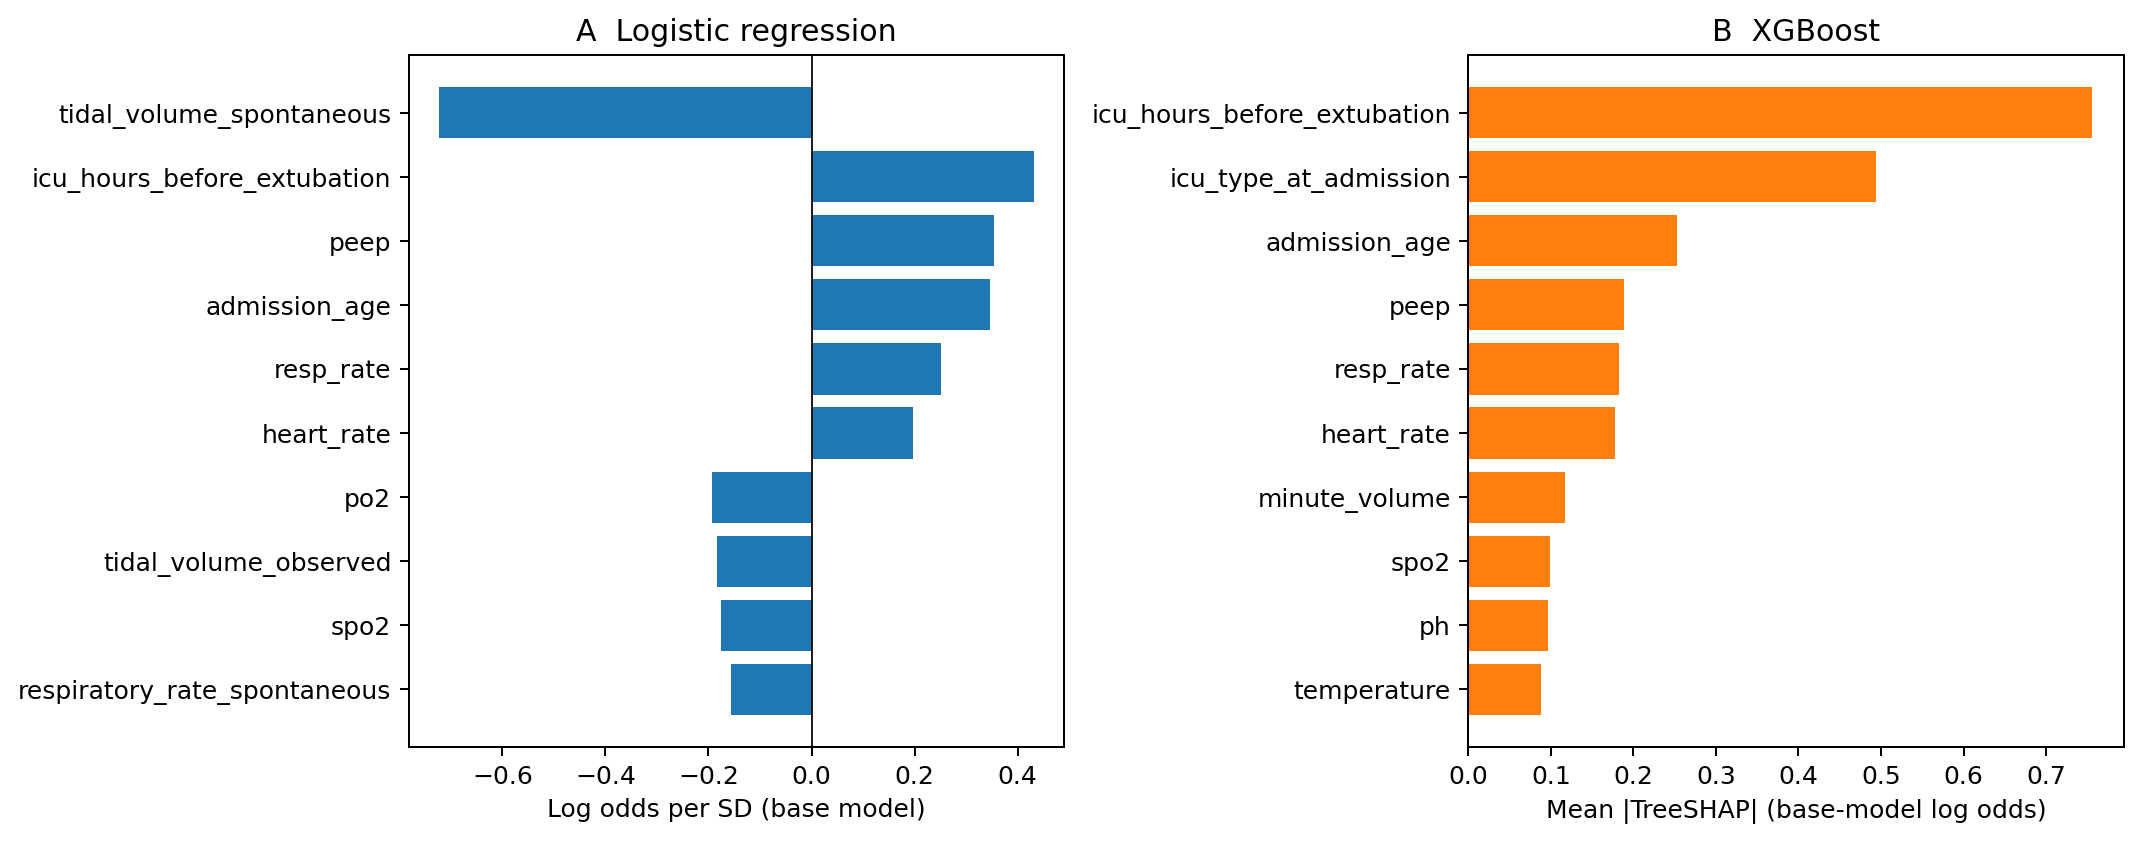

In [14]:
# Interpretation uses the primary cohort's development patients only.
lr_coefficients, xgb_importance = export_interpretation(runs["filtered_six_hour"])
display(lr_coefficients.head(10).round(3))
display(xgb_importance.head(10).round(4))
display(Image(filename=str(primary_dir / "interpretation_lr_shap.png")))

## 9. Temporal test evaluation (results)

All analyses are locked before any test patient is scored; identical reruns reload the saved results, and changed analyses are rejected. Fewer than 20 test events or non-events triggers a precision warning only.

The filtered six-hour cohort is primary. Printed and saved:
1. Table 1: development and test partitions of the primary cohort, and the patients removed by the missingness filter.
2. Table 2: test performance of every analysis with 95% CIs, and an AUROC forest plot.
3. Calibration and decision curve for the primary analysis.
4. Paired XGBoost − LR difference, and LR/XGBoost/RSBI on the same RSBI-available patients.
5. Sensitivity analyses on the test set: six-hour vs last-hour models on the same patients; full-cohort vs filtered-cohort training on the same filtered-cohort patients; and both on the test patients removed by the filter. The full-cohort comparisons change the training population and size, so they are not an isolated missingness effect.
6. AUROC for deaths and reintubations separately, missed and false alerts, and exploratory subgroups. Subgroup and error results must not be used to retune the models.

In [15]:
def final_evaluation(run):
    """Score one frozen analysis on its temporal test set and save its results."""
    bundle, df, out = run["bundle"], run["data"], run["output_dir"]
    frozen = bundle["frozen"]
    cfg = frozen["config"]
    marker = out / "final_test_started.json"
    signature = hashlib.sha256(json.dumps(frozen, sort_keys=True).encode()).hexdigest()
    model_hash = file_hash(out / "trained_models.joblib")
    if marker.exists():
        prior = json.loads(marker.read_text())
        if prior.get("analysis_signature") != signature or prior.get("model_sha256") != model_hash:
            raise RuntimeError("Models or settings changed after final evaluation started.")
        if prior["status"] == "completed":
            print("Loading saved final-test results.")
            return
        print("Resuming final evaluation with the saved models.")
    test = df.set_index("subject_id", drop=False).loc[bundle["test_ids"]].reset_index(drop=True)
    warn_small_holdout(frozen["holdout"], cfg)
    # Save the marker before evaluation so interrupted runs can resume.
    marker_info = {"analysis_signature": signature, "model_sha256": model_hash, "holdout": frozen["holdout"]}
    write_json(marker, {**marker_info, "status": "started"})
    X = test[frozen["selected_features"]]
    scores = {n: m.predict_proba(X)[:, 1] for n, m in bundle["models"].items()}
    scores["prevalence_baseline"] = np.full(len(test), bundle["development_prevalence"])
    scores["random_guess"] = np.random.default_rng(cfg["seed"] + 300).uniform(size=len(test))
    p = prediction_table(test, cfg, scores, frozen["rsbi_column"])
    p.to_csv(out / "FINAL_test_predictions.csv", index=False)
    table = comparison_tables(p, frozen["thresholds"])
    table.to_csv(out / "FINAL_test_metrics.csv", index=False)
    ci, differences = bootstrap_intervals(p, frozen["thresholds"], cfg)
    ci.to_csv(out / "FINAL_test_patient_bootstrap_CI.csv", index=False)
    differences.to_csv(out / "FINAL_paired_difference_XGB_minus_LR_CI.csv", index=False)
    outcome_component_auroc(p).to_csv(out / "FINAL_outcome_component_auroc.csv", index=False)
    subgroup_metrics(p, frozen["thresholds"], cfg).to_csv(out / "FINAL_exploratory_subgroup_metrics.csv", index=False)

    # Missed failures and false alerts at the frozen thresholds, split by outcome component.
    errors = []
    for name in MODEL_NAMES:
        flagged = p[name] >= frozen["thresholds"][name]
        for label, mask in [("missed failure (false negative)", p.y_true.eq(1) & ~flagged),
                            ("false alert (false positive)", p.y_true.eq(0) & flagged)]:
            errors.append({"model": name, "error": label, "patients": int(mask.sum()),
                **{c: int(p.loc[mask, c].sum()) for c in OUTCOME_COMPONENTS if c in p}})
    pd.DataFrame(errors).to_csv(out / "FINAL_error_summary.csv", index=False)
    write_json(marker, {**marker_info, "status": "completed"})


def evaluate_suite(runs, configs):
    """Lock every analysis, then score every test set and combine the headline metrics."""
    verify_ablation_pair(runs)
    guard_final_suite(configs)
    marker = SUITE_DIR / "final_suite_started.json"
    if not marker.exists():
        for name, cfg in configs.items():
            frozen = runs[name]["bundle"]["frozen"]
            if cfg != frozen["config"] or load_cohort(cfg)[-1] != frozen["source_hashes"]:
                raise RuntimeError("Data or settings changed since development. Refit all analyses before opening the test set.")
        write_json(marker, {"status": "started", "primary_analysis": "filtered_six_hour", "plan": suite_plan(configs),
            "model_hashes": {name: file_hash(run["output_dir"] / "trained_models.joblib") for name, run in runs.items()},
            "analysis_hashes": {name: file_hash(run["output_dir"] / "frozen_analysis.json") for name, run in runs.items()}})
    # The complete suite is locked BEFORE any overlapping test set is scored.
    rows = []
    for name, run in runs.items():
        print("Test evaluation:", name)
        final_evaluation(run)
        table = pd.read_csv(run["output_dir"] / "FINAL_test_metrics.csv")
        table = table[table.scope.eq("all_patients")].drop(columns="scope")
        ci = pd.read_csv(run["output_dir"] / "FINAL_test_patient_bootstrap_CI.csv")
        ci = ci[ci.scope.eq("all_patients") & ci.metric.isin(["auroc", "average_precision"])]
        wide = ci.pivot(index="model", columns="metric", values=["lower_95", "upper_95"])
        wide.columns = [f"{metric}_{bound}" for bound, metric in wide.columns]
        rows.append(table.merge(wide, left_on="model", right_index=True, how="left").assign(analysis=name))
    result = pd.concat(rows, ignore_index=True)
    result.to_csv(SUITE_DIR / "FINAL_analysis_comparison.csv", index=False)
    saved = json.loads(marker.read_text())
    write_json(marker, {**saved, "status": "completed"})
    return result


def test_predictions(run):
    """Saved test-set predictions of one analysis, indexed by patient."""
    return pd.read_csv(run["output_dir"] / "FINAL_test_predictions.csv", dtype={"subject_id": "string"}).set_index("subject_id")


def test_sensitivity_analyses(runs):
    """Prespecified sensitivity analyses on the test set; each row is a paired difference A − B."""
    primary = runs["filtered_six_hour"]
    cfg = primary["bundle"]["frozen"]["config"]
    reps, seed = cfg["bootstrap_replicates"], cfg["seed"] + 400
    main = test_predictions(primary)
    full = test_predictions(runs["full_six_hour"])
    removed = full.index.difference(main.index)  # test patients excluded by the missingness filter
    removed_X = runs["full_six_hour"]["data"].set_index("subject_id").loc[removed, primary["bundle"]["frozen"]["selected_features"]]
    comparisons = []
    for name in MODEL_NAMES:
        if "filtered_last_hour" in runs:
            last = test_predictions(runs["filtered_last_hour"]).loc[main.index]
            comparisons.append(("A six-hour vs B last-hour (same patients)", name, main.y_true, main[name], last[name]))
        comparisons.append(("A full-cohort vs B filtered-cohort training (filtered-cohort patients)",
            name, main.y_true, full.loc[main.index, name], main[name]))
        if len(removed):
            filtered_scores = primary["bundle"]["models"][name].predict_proba(removed_X)[:, 1]
            comparisons.append(("A full-cohort vs B filtered-cohort training (patients removed by filter)",
                name, full.loc[removed, "y_true"], full.loc[removed, name], filtered_scores))
    rows = []
    for i, (label, name, y, a, b) in enumerate(comparisons):
        for r in paired_bootstrap(y, a, b, reps, seed + i):
            rows.append({"comparison": label, "model": name, "patients": len(y), "events": int(np.sum(y)), **r})
    table = pd.DataFrame(rows).rename(columns={"a": "A", "b": "B", "a_minus_b": "A_minus_B"})
    table.to_csv(SUITE_DIR / "FINAL_sensitivity_analyses.csv", index=False)
    return table

In [16]:
final_results = evaluate_suite(runs, RUN_CONFIGS)
TABLE_1 = cohort_table(runs)
TABLE_1.to_csv(SUITE_DIR / "table1_cohort.csv", index=False)
print("Table 1: primary cohort (development and temporal test) and patients removed by the missingness filter")
display(TABLE_1)

summary_columns = ["analysis", "model", "n", "events", "prevalence", "auroc", "auroc_lower_95", "auroc_upper_95",
    "average_precision", "average_precision_lower_95", "average_precision_upper_95", "brier", "scaled_brier",
    "calibration_slope", "observed_expected_ratio", "threshold", "sensitivity", "specificity", "ppv", "npv"]
print("Table 2: temporal test performance (primary and prespecified sensitivity analyses)")
display(final_results[summary_columns].round(3))
plot_auroc_forest(final_results, SUITE_DIR / "FINAL_auroc_forest.png", "Temporal test AUROC")
display(Image(filename=str(SUITE_DIR / "FINAL_auroc_forest.png")))
primary_test = test_predictions(runs["filtered_six_hour"])
display(Image(filename=str(plot_calibration_and_utility(primary_test, CONFIG["decision_curve_max_threshold"],
    SUITE_DIR, "Primary analysis: temporal test"))))

print("XGBoost minus LR, paired bootstrap (primary analysis)")
display(pd.read_csv(primary_dir / "FINAL_paired_difference_XGB_minus_LR_CI.csv").round(3))
test_rsbi = rsbi_comparison(pd.read_csv(primary_dir / "FINAL_test_metrics.csv"),
    pd.read_csv(primary_dir / "FINAL_test_patient_bootstrap_CI.csv"))
test_rsbi.to_csv(SUITE_DIR / "FINAL_rsbi_comparison.csv", index=False)
print("LR, XGBoost and RSBI on the same RSBI-available test patients (RSBI threshold 105)")
display(test_rsbi.round(3))

print("Sensitivity analyses: paired differences A − B with 95% CIs")
display(test_sensitivity_analyses(runs).round(3))
print("Deaths and reintubations separately against non-events (primary analysis)")
display(pd.read_csv(primary_dir / "FINAL_outcome_component_auroc.csv").round(3))
print("Missed failures and false alerts at the frozen thresholds (primary analysis)")
display(pd.read_csv(primary_dir / "FINAL_error_summary.csv"))
print("Exploratory subgroups (primary analysis)")
display(pd.read_csv(primary_dir / "FINAL_exploratory_subgroup_metrics.csv")[
    ["variable", "group", "model", "n", "events", "auroc", "auroc_lower_95", "auroc_upper_95"]].round(3))

Development complete for all analyses. Real holdouts remain unscored.


## Generative AI declaration

We declare the use of claude [claude.ai] and ChatGPT[openai.com] to check the code, formate and structure it. We also used them to check for grammar, sentence structure and overall flow of the code and the report. 